# Fashion-MNIST

AE, Sparse AE, VAE, Vanilla GAN, DCGAN, dan DDPM. Semua kode ada di notebook ini.

Pilih kernel `mopad_gpu`, lalu Restart Kernel dan Run All. Setiap model dilatih dari awal dengan output per epoch. Evaluasi dan lima figur dibuat dari model yang baru dilatih. Hasil disimpan ke folder `results` yang dibuat otomatis.

Laporan Word/PDF yang disertakan berisi hasil eksperimen sebelumnya. Cocokkan angkanya setelah eksekusi baru selesai.


## Library

Gunakan environment PyTorch dengan CUDA. Jika dependensi belum tersedia, jalankan di terminal environment tersebut:

```bash
python -m pip install torch torchvision numpy pandas matplotlib scikit-learn scipy scikit-image torchmetrics[image] torch-fidelity Pillow
```


In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')

import contextlib
import csv
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
from torchmetrics.functional.image import structural_similarity_index_measure
from torchmetrics.image.fid import FrechetInceptionDistance

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

In [2]:
def set_seed(seed):
    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def sync_gpu(device):
    if str(device).startswith('cuda'):
        torch.cuda.synchronize()


def write_json(path, value):
    path = Path(path)
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    temp.replace(path)


def environment(device):
    import torchvision
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'torch': torch.__version__, 'torchvision': torchvision.__version__,
            'cuda': torch.version.cuda, 'device': str(device),
            'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            'deterministic_algorithms': True, 'cudnn_benchmark': False,
            'training_precision': 'float32; DDPM autocast bfloat16 on supported CUDA',
            'evaluation_precision': 'float32 (FID accumulators float64)'}

## Pengaturan


In [3]:
root = Path.cwd()
if not (root / 'experiment.ipynb').is_file() and (root / 'gslc2' / 'experiment.ipynb').is_file():
    root = root / 'gslc2'

tes_cepat = False
epochs = 88
cfg = {
    'seed': 42,
    'batch_size': 128,
    'latent_dim': 64,
    'gan_latent_dim': 100,
    'sparsity_lambda': 0.001,
    'learning_rate': 0.001,
    'gan_learning_rate': 0.0002,
    'ddpm_learning_rate': 0.0002,
    'ddpm_steps': 200,
    'ddpm_channels': 32,
    'epochs': {name: epochs for name in (
        'classifier', 'ae', 'sparse_ae', 'vae',
        'frozen_decoder', 'gan', 'dcgan', 'ddpm'
    )},
    'fid_samples': 7000,
    'fid_batch_size': 64,
    'sampling_batch_size': 128,
    'latency_repeats': 10,
    'latency_warmup': 3,
    'device': 'auto',
}
if tes_cepat:
    cfg['epochs'] = {name: 1 for name in cfg['epochs']}
    cfg['ddpm_steps'] = 10
    cfg['fid_samples'] = 64
    cfg['latency_repeats'] = 2
    cfg['latency_warmup'] = 1
cfg['smoke'] = tes_cepat
out = root / ('results_smoke' if tes_cepat else 'results')
out.mkdir(parents=True, exist_ok=True)
write_json(out / 'config.json', cfg)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
set_seed(cfg['seed'])
print('Device:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')
keys = ['seed', 'batch_size', 'latent_dim', 'gan_latent_dim', 'ddpm_steps']
display(pd.DataFrame({'Parameter': keys, 'Nilai': [cfg[k] for k in keys]}))

Device: NVIDIA GeForce RTX 5050 Laptop GPU


,Parameter,Nilai
0,seed,42
1,batch_size,128
2,latent_dim,64
3,gan_latent_dim,100
4,ddpm_steps,200


## Dataset

In [4]:
def load_data(root, out, seed, device, smoke=False):
    train = FashionMNIST(root=str(root), train=True, download=True)
    test = FashionMNIST(root=str(root), train=False, download=True)
    images = torch.cat([train.data, test.data]).unsqueeze(1)
    labels = torch.cat([train.targets, test.targets])
    indices = np.arange(len(images))
    train_idx, remaining = train_test_split(indices, test_size=0.2, random_state=seed,
                                           stratify=labels.numpy())
    val_idx, test_idx = train_test_split(remaining, test_size=0.5, random_state=seed,
                                        stratify=labels.numpy()[remaining])
    split_file = Path(out) / 'split_indices.npz'
    if split_file.exists():
        saved = np.load(split_file)
        for key, value in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
            if not np.array_equal(saved[key], value):
                raise ValueError('Existing split differs: use a new output directory.')
    else:
        np.savez_compressed(split_file, train=train_idx, val=val_idx, test=test_idx)
    result = {}
    for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
        if smoke:
            idx = idx[:512 if name == 'train' else 128]
        result[name] = TensorDataset(images[idx].float().to(device) / 255,
                                     labels[idx].long().to(device))
    return result


def loader(dataset, batch_size, train=False, seed=42):
    return DataLoader(dataset, batch_size=batch_size, shuffle=train, num_workers=0,
                      generator=torch.Generator().manual_seed(seed), drop_last=False)

## AE dan Classifier

AE, Sparse AE, classifier, dan decoder dibuat sesuai arsitektur tugas. Cara training memakai rujukan [PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).


In [5]:
class Decoder(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())

    def forward(self, z):
        return self.net(z).reshape(-1, 1, 28, 28)

class Autoencoder(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, latent), nn.ReLU())
        self.decoder = Decoder(latent)

    def forward(self, x):
        return self.decoder(self.encoder(x))

class Classifier(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, latent)
        self.fc3 = nn.Linear(latent, 10)

    def encode(self, x):
        return F.relu(self.fc2(F.relu(self.fc1(x.flatten(1)))))

    def forward(self, x):
        return self.fc3(self.encode(x))

    def transpose_latent(self, z):
        h = F.relu(z @ self.fc2.weight)
        return torch.sigmoid(h @ self.fc1.weight).reshape(-1, 1, 28, 28)

    def transpose_class(self, y):
        one_hot = F.one_hot(y, 10).float()
        return self.transpose_latent(F.relu(one_hot @ self.fc3.weight))

## VAE

Rujukan reparameterisasi dan BCE + KL: [contoh VAE PyTorch](https://github.com/pytorch/examples/blob/main/vae/main.py). Layer disesuaikan menjadi 784-256-64 dan output gambar 28 x 28.


In [6]:
class VAE(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, latent)
        self.logvar = nn.Linear(256, latent)
        self.decoder = Decoder(latent)

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

## GAN dan DCGAN

Rujukan training G/D dan blok konvolusi: [tutorial DCGAN PyTorch](https://github.com/pytorch/tutorials/blob/main/beginner_source/dcgan_faces_tutorial.py). Vanilla GAN memakai MLP; DCGAN disesuaikan untuk gambar satu kanal 28 x 28. Discriminator mengeluarkan logits dan loss memakai BCEWithLogits.


In [7]:
class GAN(nn.Module):
    def __init__(self, latent=100, convolutional=False):
        super().__init__()
        self.latent = latent
        self.convolutional = convolutional
        if convolutional:
            self.generator = nn.Sequential(
                nn.ConvTranspose2d(latent, 128, 7, bias=False), nn.BatchNorm2d(128), nn.ReLU(),
                nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
                nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())
            self.discriminator = nn.Sequential(
                nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),
                nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
                nn.Conv2d(128, 1, 7), nn.Flatten())
            self.apply(self._initialize)
        else:
            self.generator = nn.Sequential(
                nn.Linear(latent, 256), nn.LeakyReLU(0.2),
                nn.Linear(256, 512), nn.LeakyReLU(0.2),
                nn.Linear(512, 784), nn.Tanh())
            self.discriminator = nn.Sequential(
                nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
                nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(module.weight, 0, 0.02)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.normal_(module.weight, 1, 0.02)
            nn.init.zeros_(module.bias)

    def generate(self, z):
        if self.convolutional:
            z = z[:, :, None, None]
        return self.generator(z).reshape(-1, 1, 28, 28)

    def sample(self, z):
        return (self.generate(z) + 1) / 2

## DDPM

Rujukan cosine schedule dan rumus posterior: [OpenAI improved-diffusion](https://github.com/openai/improved-diffusion/blob/main/improved_diffusion/gaussian_diffusion.py). U-Net kecil di bawah dibuat khusus untuk eksperimen ini; bukan salinan U-Net repositori tersebut.


In [8]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim
        self.proj = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):
        freq = torch.exp(-math.log(10000) * torch.arange(
            self.dim // 2, device=t.device) / (self.dim // 2 - 1))
        phase = t.float()[:, None] * freq[None]
        return self.proj(torch.cat([phase.sin(), phase.cos()], dim=1))

class ResBlock(nn.Module):
    def __init__(self, cin, cout, time_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.time = nn.Linear(time_dim, cout)
        self.norm2 = nn.GroupNorm(8, cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, t):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time(F.silu(t))[:, :, None, None]
        return self.skip(x) + self.conv2(F.silu(self.norm2(h)))

class NoiseUNet(nn.Module):
    def __init__(self, channels=32):
        super().__init__()
        c = channels
        self.time = TimeEmbedding()
        self.input = nn.Conv2d(1, c, 3, padding=1)
        self.down1 = ResBlock(c, c)
        self.down2 = ResBlock(c, c * 2)
        self.middle1 = ResBlock(c * 2, c * 4)
        self.middle2 = ResBlock(c * 4, c * 2)
        self.up2 = ResBlock(c * 4, c)
        self.up1 = ResBlock(c * 2, c)
        self.output = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))

    def forward(self, x, timestep):
        t = self.time(timestep)
        h1 = self.down1(self.input(x), t)
        h2 = self.down2(F.avg_pool2d(h1, 2), t)
        h = self.middle2(self.middle1(F.avg_pool2d(h2, 2), t), t)
        h = self.up2(torch.cat([F.interpolate(h, size=h2.shape[-2:], mode='nearest'), h2], 1), t)
        h = self.up1(torch.cat([F.interpolate(h, size=h1.shape[-2:], mode='nearest'), h1], 1), t)
        return self.output(h)

class DDPM(nn.Module):
    def __init__(self, steps=200, channels=32):
        super().__init__()
        self.steps = steps
        self.network = NoiseUNet(channels)
        # Cosine schedule.
        t = torch.linspace(0, steps, steps + 1, dtype=torch.float64) / steps
        cumulative = torch.cos((t + 0.008) / 1.008 * math.pi / 2).square()
        cumulative = cumulative / cumulative[0]
        # Float64 menjaga presisi koefisien pada t=0.
        betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(max=0.999)
        alphas = 1 - betas
        abar = torch.cumprod(alphas, 0)
        previous = F.pad(abar[:-1], (1, 0), value=1)
        for key, value in {
            'betas': betas, 'alphas': alphas, 'abar': abar,
            'posterior_var': betas * (1 - previous) / (1 - abar),
            'posterior_c1': betas * previous.sqrt() / (1 - abar),
            'posterior_c2': (1 - previous) * alphas.sqrt() / (1 - abar)
        }.items():
            self.register_buffer(key, value.float())

    def loss(self, x, t=None, noise=None):
        if t is None:
            t = torch.randint(self.steps, (len(x),), device=x.device)
        if noise is None:
            noise = torch.randn_like(x)
        a = self.abar[t, None, None, None]
        noisy = a.sqrt() * (2 * x - 1) + (1 - a).sqrt() * noise
        return F.mse_loss(self.network(noisy, t), noise)

    @torch.no_grad()
    def sample(self, n, trajectory=False, generator=None):
        device = self.betas.device
        x = torch.randn(n, 1, 28, 28, device=device, generator=generator)
        frames = [(x.clone() + 1) / 2] if trajectory else []
        marks = set(torch.linspace(self.steps - 1, 0, 7).long().tolist())
        for step in range(self.steps - 1, -1, -1):
            t = torch.full((n,), step, device=device, dtype=torch.long)
            epsilon = self.network(x, t)
            x0 = ((x - (1 - self.abar[step]).sqrt() * epsilon) /
                  self.abar[step].sqrt()).clamp(-1, 1)
            mean = self.posterior_c1[step] * x0 + self.posterior_c2[step] * x
            if step > 0:
                noise = torch.randn(x.shape, device=device, generator=generator)
                x = mean + self.posterior_var[step].sqrt() * noise
            else:
                x = mean
            if trajectory and step in marks:
                frames.append(((x.clone() + 1) / 2).clamp(0, 1))
        result = ((x + 1) / 2).clamp(0, 1)
        return (result, frames) if trajectory else result

def build_models(cfg):
    d = cfg['latent_dim']
    return {
        'classifier': Classifier(d), 'ae': Autoencoder(d),
        'sparse_ae': Autoencoder(d), 'vae': VAE(d),
        'frozen_decoder': Decoder(d),
        'gan': GAN(cfg['gan_latent_dim']),
        'dcgan': GAN(cfg['gan_latent_dim'], convolutional=True),
        'ddpm': DDPM(cfg['ddpm_steps'], cfg['ddpm_channels'])
    }

## Fungsi Training


In [9]:
def get_loss(name, model, x, y, clf, cfg):
    parts = {}
    logits = None
    if name == 'classifier':
        logits = model(x)
        loss = F.cross_entropy(logits, y)
    elif name == 'frozen_decoder':
        with torch.no_grad():
            z = clf.encode(x)
        loss = F.mse_loss(model(z), x)
        parts['reconstruction_loss'] = loss
    elif name in ('ae', 'sparse_ae'):
        z = model.encoder(x)
        recon = F.mse_loss(model.decoder(z), x)
        loss = recon
        parts['reconstruction_loss'] = recon
        if name == 'sparse_ae':
            penalty = cfg['sparsity_lambda'] * z.abs().mean()
            loss = loss + penalty
            parts['sparsity_penalty'] = penalty
    elif name == 'vae':
        recon, mu, logvar = model(x)
        bce = F.binary_cross_entropy(recon, x, reduction='sum') / len(x)
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
        loss = bce + kl
        parts = {'reconstruction_loss': bce, 'kl_loss': kl}
    elif name == 'ddpm':
        loss = model.loss(x)
    else:
        raise ValueError(name)
    return loss, parts, logits


@torch.no_grad()
def validate(name, model, dataset, clf, cfg, device):
    model.eval()
    total, count, correct = 0., 0, 0
    # Noise validasi tetap setiap epoch.
    with torch.random.fork_rng(devices=[torch.cuda.current_device()] if device.type == 'cuda' else []):
        torch.manual_seed(cfg['seed'] + 991)
        for x, y in loader(dataset, cfg['batch_size']):
            loss, _, logits = get_loss(name, model, x, y, clf, cfg)
            if logits is not None:
                correct += int((logits.argmax(1) == y).sum())
            total += float(loss) * len(x)
            count += len(x)
    return total / count, correct / count if name == 'classifier' else None


def train_model(name, models, data, cfg, out, device):
    set_seed(cfg['seed'])
    model = models[name].to(device)
    model.load_state_dict(start_weights[name])
    model.requires_grad_(True)
    clf = models['classifier'].to(device)
    if name == 'frozen_decoder':
        clf.eval().requires_grad_(False)
    model_dir = out / 'checkpoints'
    model_dir.mkdir(exist_ok=True)
    best_path = model_dir / f'{name}_best.pt'
    is_gan = name in ('gan', 'dcgan')
    lr = cfg['gan_learning_rate'] if is_gan else (
        cfg['ddpm_learning_rate'] if name == 'ddpm' else cfg['learning_rate'])
    if is_gan:
        opts = [torch.optim.Adam(model.generator.parameters(), lr=lr, betas=(0.5, 0.999)),
                      torch.optim.Adam(model.discriminator.parameters(), lr=lr, betas=(0.5, 0.999))]
    else:
        opts = [torch.optim.Adam(model.parameters(), lr=lr)]
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opts[0], factor=0.5, patience=5, min_lr=1e-5) if name == 'classifier' else None
    history, best = [], float('inf')
    epochs = cfg['epochs'][name]
    print(f'{name}: training {epochs} epoch', flush=True)
    for epoch in range(epochs):
        model.train()
        total, total_d, count, correct = 0., 0., 0, 0
        components = {}
        sync_gpu(device)
        begin = time.perf_counter()
        for x, y in loader(data['train'], cfg['batch_size'], train=True,
                           seed=cfg['seed'] + epoch):
            if is_gan:
                opt_g, opt_d = opts
                model.discriminator.requires_grad_(True)
                opt_d.zero_grad(set_to_none=True)
                real_logits = model.discriminator(2 * x - 1)
                z = torch.randn(len(x), model.latent, device=device)
                fake = model.generate(z)
                fake_logits = model.discriminator(fake.detach())
                d_loss = (F.binary_cross_entropy_with_logits(real_logits, torch.ones_like(real_logits)) +
                          F.binary_cross_entropy_with_logits(fake_logits, torch.zeros_like(fake_logits)))
                d_loss.backward()
                opt_d.step()
                model.discriminator.requires_grad_(False)
                opt_g.zero_grad(set_to_none=True)
                generated_logits = model.discriminator(fake)
                loss = F.binary_cross_entropy_with_logits(generated_logits, torch.ones_like(generated_logits))
                loss.backward()
                opt_g.step()
                total_d += float(d_loss.detach()) * len(x)
            else:
                opts[0].zero_grad(set_to_none=True)
                use_amp = (name == 'ddpm' and device.type == 'cuda' and torch.cuda.is_bf16_supported())
                amp = torch.autocast('cuda', dtype=torch.bfloat16) if use_amp else contextlib.nullcontext()
                with amp:
                    loss, parts, logits = get_loss(name, model, x, y, clf, cfg)
                    if logits is not None:
                        correct += int((logits.detach().argmax(1) == y).sum())
                for key, value in parts.items():
                    components[key] = components.get(key, 0.) + float(value.detach()) * len(x)
                loss.backward()
                if name == 'ddpm':
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opts[0].step()
            if not torch.isfinite(loss):
                raise FloatingPointError(f'{name}: nonfinite loss at epoch {epoch + 1}')
            total += float(loss.detach()) * len(x)
            count += len(x)
        sync_gpu(device)
        seconds = time.perf_counter() - begin
        row = {'epoch': epoch + 1, 'train_loss': total / count,
                  'training_seconds': seconds, 'learning_rate': opts[0].param_groups[0]['lr']}
        row.update({key: value / count for key, value in components.items()})
        if name == 'classifier':
            row['train_accuracy'] = correct / count
        if is_gan:
            row['discriminator_loss'] = total_d / count
            score = -(epoch + 1)  # GAN memakai epoch terakhir.
        else:
            val_loss, val_accuracy = validate(name, model, data['val'], clf, cfg, device)
            row['val_loss'] = val_loss
            if val_accuracy is not None:
                row['val_accuracy'] = val_accuracy
            score = -val_accuracy if name == 'classifier' else val_loss
            if scheduler is not None:
                scheduler.step(val_loss)
        history.append(row)
        if score < best:
            best = score
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'selection_score': score}, best_path)
        write_json(out / f'{name}_history.json', history)
        write_json(out / 'progress.json', {'stage': 'training', 'model': name,
                   'epoch': epoch + 1, 'target_epochs': epochs, 'last_record': row})
        line = f'epoch {epoch + 1}/{epochs} {"g_loss" if is_gan else "loss"}={row["train_loss"]:.6f}'
        if 'discriminator_loss' in row:
            line += f' d_loss={row["discriminator_loss"]:.6f}'
        if 'val_loss' in row:
            line += f' val_loss={row["val_loss"]:.6f}'
        if name == 'classifier':
            line += f' train_acc={row["train_accuracy"]:.2%} val_acc={row["val_accuracy"]:.2%}'
        print(line + f' time={seconds:.1f}s', flush=True)
    selected = torch.load(best_path, map_location=device, weights_only=False)
    model.load_state_dict(selected['model'])
    model.eval()
    write_json(out / f'{name}_selection.json', {'epoch': selected['epoch'],
               'criterion': 'last epoch' if is_gan else ('validation accuracy' if name == 'classifier' else 'validation objective'),
               'epochs_trained': len(history)})
    return history

## Fungsi Plot


In [10]:
NAMES = {'ae': 'Vanilla AE', 'sparse_ae': 'Sparse AE', 'vae': 'VAE',
         'gan': 'Vanilla GAN', 'dcgan': 'DCGAN', 'ddpm': 'DDPM'}
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


def image(ax, img, title=None):
    ax.imshow(img.detach().cpu().squeeze().numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)


def grid(ax, img, nrow=4, title=None):
    pixels = make_grid(img.detach().cpu().float(), nrow=nrow, padding=2, pad_value=0.15)
    ax.imshow(pixels.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=11)


def save(fig, out, stem):
    fig.savefig(out / 'figures' / f'{stem}.png', dpi=240, bbox_inches='tight')
    fig.savefig(out / 'figures' / f'{stem}.pdf', bbox_inches='tight')
    plt.close(fig)


@torch.inference_mode()
def make_figures(models, data, cfg, out, device, fake_images):
    set_seed(cfg['seed'] + 3000)
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
    x, y = data['test'].tensors
    # Gambar pertama setiap kelas pada test set.
    indices = [int(torch.where(y == label)[0][0]) for label in range(10)]
    selected = x[indices]
    info = {'reconstruction_test_positions': indices,
                  'reconstruction_selection': 'first occurrence of each class in persisted test order'}
    recons = [selected, models['ae'](selected), models['sparse_ae'](selected),
              models['vae'].decoder(models['vae'].encode(selected)[0])]
    fig, axes = plt.subplots(4, 10, figsize=(15, 6))
    for r, (row, title) in enumerate(zip(recons, ['Asli', 'Vanilla AE', 'Sparse AE', 'VAE'])):
        for c, sample in enumerate(row):
            image(axes[r, c], sample, CLASSES[c] if r == 0 else None)
        axes[r, 0].set_ylabel(title, fontsize=10)
    fig.suptitle('Gambar 1. Rekonstruksi')
    fig.tight_layout()
    save(fig, out, 'fig1_reconstructions')

    fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
    for ax, name in zip(axes, ['vae', 'gan', 'dcgan', 'ddpm']):
        grid(ax, fake_images[name][:16].float() / 255, title=NAMES[name])
    fig.suptitle('Gambar 2. Sampel Acak')
    fig.tight_layout()
    save(fig, out, 'fig2_random_sampling')

    clf = models['classifier']
    latent = clf.encode(selected)
    frozen = models['frozen_decoder'](latent)
    fig = plt.figure(figsize=(16, 9), layout='constrained')
    outer = fig.subfigures(2, 2)
    panels = [
        ('A. Asli test images', [('Asli', selected)]),
        ('B. Transpose Bobot', [('Dari Label Asli', clf.transpose_class(y[indices])),
                                            ('Dari Fitur', clf.transpose_latent(latent))]),
        ('C. Rekonstruksi', [('Classifier Beku + Decoder', frozen), ('Vanilla AE', recons[1])]),
        ('D. Sampling Fitur Classifier', [('Gaussian + Decoder',
          torch.load(out / 'samples/classifier_prior.pt', weights_only=True)[:10])])]
    for subfig, (title, rows) in zip(outer.flat, panels):
        subfig.suptitle(title, fontsize=11)
        axes = subfig.subplots(len(rows), 1, squeeze=False)
        for ax, (label, samples) in zip(axes[:, 0], rows):
            grid(ax, samples, nrow=5, title=label)
    fig.suptitle('Gambar 3. Eksperimen Classifier', fontsize=14)
    save(fig, out, 'fig3_classifier_experiments')

    # Kelas endpoint GAN ditentukan oleh classifier.
    endpoint_classes = [0, 7]
    endpoint_positions = [int(torch.where(y == label)[0][0]) for label in endpoint_classes]
    endpoints = x[endpoint_positions]
    alpha = torch.tensor([0., .2, .4, .6, .8, 1.], device=device)[:, None]
    fig, axes = plt.subplots(5, 6, figsize=(11, 9))
    info['interpolation_real_test_positions'] = endpoint_positions
    info['gan_endpoint_selection'] = 'first generated endpoint predicted as target class by trained classifier; no labels condition generator'
    for r, name in enumerate(['ae', 'sparse_ae', 'vae', 'gan', 'dcgan']):
        model = models[name]
        if name in ('ae', 'sparse_ae'):
            z = model.encoder(endpoints)
            result = model.decoder((1 - alpha) * z[0] + alpha * z[1])
        elif name == 'vae':
            z = model.encode(endpoints)[0]
            result = model.decoder((1 - alpha) * z[0] + alpha * z[1])
        else:
            pool = torch.randn(1024, model.latent, device=device)
            images = model.sample(pool)
            scores = clf(images).softmax(1)
            chosen = []
            for label in endpoint_classes:
                matches = torch.where(scores.argmax(1) == label)[0]
                chosen.append(int(matches[0]) if len(matches) else int(scores[:, label].argmax()))
            z = pool[chosen]
            info[f'{name}_endpoint_predicted_classes'] = scores[chosen].argmax(1).cpu().tolist()
            info[f'{name}_endpoint_confidences'] = scores[chosen].max(1).values.cpu().tolist()
            result = model.sample((1 - alpha) * z[0] + alpha * z[1])
        for c, sample in enumerate(result):
            image(axes[r, c], sample, f'alpha={float(alpha[c, 0]):.1f}' if r == 0 else None)
        axes[r, 0].set_ylabel(NAMES[name])
    fig.suptitle('Gambar 4. Interpolasi Laten', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, .94))
    save(fig, out, 'fig4_latent_interpolation')

    fig = plt.figure(figsize=(16, 12), layout='constrained')
    spec = fig.add_gridspec(3, 3, height_ratios=[1, 1, .8])
    for index, name in enumerate(['ae', 'sparse_ae', 'vae', 'gan', 'dcgan', 'ddpm']):
        ax = fig.add_subplot(spec[index // 3, index % 3])
        history = json.loads((out / f'{name}_history.json').read_text())
        epochs = [row['epoch'] for row in history]
        ax.plot(epochs, [row['train_loss'] for row in history], label='G' if name in ('gan', 'dcgan') else 'Train', color='black')
        if name in ('gan', 'dcgan'):
            ax.plot(epochs, [row['discriminator_loss'] for row in history], label='D', color='black', linestyle='--')
        else:
            ax.plot(epochs, [row['val_loss'] for row in history], label='Val', color='black', linestyle='--')
        ax.set(title=NAMES[name], xlabel='Epoch', ylabel='Loss')
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    _, frames = models['ddpm'].sample(1, trajectory=True)
    trajectory_spec = spec[2, :].subgridspec(1, len(frames))
    marks = sorted(set(torch.linspace(cfg['ddpm_steps'] - 1, 0, 7).long().tolist()), reverse=True)
    labels = [f'x_T (T={cfg["ddpm_steps"]})'] + [f'x_{t}' for t in marks]
    for i, (snapshot, label) in enumerate(zip(frames, labels)):
        image(fig.add_subplot(trajectory_spec[0, i]), snapshot.clamp(0, 1), label)
    fig.suptitle('Gambar 5. Loss Training dan Denoising', fontsize=13)
    save(fig, out, 'fig5_training_and_diffusion')
    write_json(out / 'figure_provenance.json', info)

## Fungsi Evaluasi

MSE, PSNR, SSIM, FID, dan waktu proses. Implementasi FID memakai [TorchMetrics](https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance).


In [11]:
@torch.inference_mode()
def reconstruct(name, model, x, clf):
    if name == 'vae':
        return model.decoder(model.encode(x)[0])  # Rekonstruksi dari posterior mean.
    if name == 'frozen_decoder':
        return model(clf.encode(x))
    if name == 'transpose_class':
        return clf.transpose_class(clf(x).argmax(1))
    if name == 'transpose_latent':
        return clf.transpose_latent(clf.encode(x))
    return model(x)


@torch.inference_mode()
def reconstruction_metrics(name, model, dataset, clf, batch_size):
    values = []
    for x, _ in loader(dataset, batch_size):
        result = reconstruct(name, model, x, clf).clamp(0, 1)
        mse = (result - x).square().flatten(1).mean(1)
        psnr = -10 * mse.clamp_min(1e-12).log10()
        ssim = structural_similarity_index_measure(result, x, data_range=1., reduction='none')
        values.append(torch.stack([mse, psnr, ssim], 1).cpu())
    stacked = torch.cat(values).double()
    mean = stacked.mean(0)
    return dict(zip(['test_mse', 'test_psnr_db', 'test_ssim'], mean.tolist()))


@torch.inference_mode()
def sample_model(name, model, n, device):
    if name == 'ddpm':
        return model.sample(n)
    if name == 'vae':
        return model.decoder(torch.randn(n, model.mu.out_features, device=device))
    return model.sample(torch.randn(n, model.latent, device=device))


@torch.inference_mode()
def measure_time(fn, cfg, device):
    for _ in range(cfg['latency_warmup']):
        fn()
    timings = []
    for _ in range(cfg['latency_repeats']):
        sync_gpu(device)
        start = time.perf_counter()
        fn()
        sync_gpu(device)
        timings.append((time.perf_counter() - start) * 1000)
    return {'latency_mean_ms_batch64': float(np.mean(timings)),
            'latency_median_ms_batch64': float(np.median(timings)),
            'latency_std_ms_batch64': float(np.std(timings)),
            'latency_raw_ms': timings}


@torch.inference_mode()
def generate_samples(name, model, cfg, out, device):
    path = out / 'samples' / f'{name}.pt'
    set_seed(cfg['seed'] + 1000)
    batches, count = [], 0
    while count < cfg['fid_samples']:
        n = min(cfg['sampling_batch_size'], cfg['fid_samples'] - count)
        images = sample_model(name, model, n, device)
        batches.append((images.clamp(0, 1) * 255).round().to(torch.uint8).cpu())
        count += n
        if count % (cfg['sampling_batch_size'] * 10) == 0 or count == cfg['fid_samples']:
            print(f'{name}: {count}/{cfg["fid_samples"]} sampel', flush=True)
        write_json(out / 'progress.json', {'stage': 'sampling', 'model': name,
                   'samples': count, 'target': cfg['fid_samples']})
    result = torch.cat(batches)
    torch.save(result, path)
    return result


@torch.inference_mode()
def check_classifier(models, data, cfg, out):
    clf = models['classifier']
    x, y = data['test'].tensors
    features, predictions = [], []
    for xb, _ in loader(data['test'], cfg['batch_size']):
        features.append(clf.encode(xb))
        predictions.append(clf(xb).argmax(1))
    z = torch.cat(features)
    accuracy = float((torch.cat(predictions) == y).float().mean())
    result = {'test_accuracy': accuracy, 'minimum_required_accuracy': 0.88,
              'accuracy_requirement_met': accuracy >= 0.88,
              'sampling_statistics_source': 'test split, explicitly required by assignment; not used for training',
              'feature_mean': z.mean(0).cpu().tolist(),
              'feature_std': z.std(0, unbiased=False).cpu().tolist()}
    for label, model in [('classifier', clf), ('ae', models['ae']), ('sparse_ae', models['sparse_ae'])]:
        encoded = []
        for xb, _ in loader(data['test'], cfg['batch_size']):
            encoded.append(model.encode(xb) if label == 'classifier' else model.encoder(xb))
        latent = torch.cat(encoded)
        result[f'{label}_latent_zero_fraction'] = float((latent.abs() < 1e-6).float().mean())
        result[f'{label}_latent_mean_abs'] = float(latent.abs().mean())
    weights = {}
    for name in ['fc1', 'fc2', 'fc3']:
        w = getattr(clf, name).weight.detach()
        identity = torch.eye(w.shape[1], device=w.device)
        weights[name] = {'shape_out_in': list(w.shape),
                         'rank': int(torch.linalg.matrix_rank(w)),
                         'relative_gram_identity_error': float(torch.linalg.norm(w.T @ w - identity) /
                                                               torch.linalg.norm(identity))}
    result['weights'] = weights
    result['transpose_latent_metrics'] = reconstruction_metrics('transpose_latent', None,
                                                data['test'], clf, cfg['batch_size'])
    # Metrik proyeksi kelas memakai prediksi classifier.
    result['transpose_predicted_class_metrics'] = reconstruction_metrics('transpose_class', None,
                                                data['test'], clf, cfg['batch_size'])
    set_seed(cfg['seed'] + 2000)
    samples = z.mean(0) + z.std(0, unbiased=False) * torch.randn(64, z.shape[1], device=z.device)
    result['sampled_latent_negative_fraction'] = float((samples < 0).float().mean())
    before_relu = clf.fc1(x.flatten(1))
    result['classifier_first_relu_negative_input_fraction'] = float((before_relu < 0).float().mean())
    torch.save(models['frozen_decoder'](samples).cpu(), out / 'samples/classifier_prior.pt')
    write_json(out / 'classifier_diagnostics.json', result)
    return result


@torch.inference_mode()
def evaluate(models, data, cfg, out, device):
    (out / 'samples').mkdir(exist_ok=True)
    (out / 'figures').mkdir(exist_ok=True)
    set_seed(cfg['seed'] + 500)
    rows = []
    x64 = data['test'].tensors[0][:64]
    for name in ['ae', 'sparse_ae', 'vae', 'gan', 'dcgan', 'ddpm', 'frozen_decoder']:
        print(f'Evaluasi {name}', flush=True)
        model = models[name]
        history = json.loads((out / f'{name}_history.json').read_text(encoding='utf-8'))
        row = {'model': name,
               'latent_dimension': cfg['gan_latent_dim'] if name in ('gan', 'dcgan') else (
                   '1x28x28 image noise' if name == 'ddpm' else cfg['latent_dim']),
               'epochs_trained': len(history),
               'training_mean_seconds_epoch': float(np.mean([r['training_seconds'] for r in history])),
               'test_mse': None, 'test_psnr_db': None, 'test_ssim': None, 'fid_inception2048': None,
               'checkpoint_selection': json.loads((out / f'{name}_selection.json').read_text())['criterion'],
               'stability_note': 'Finite recorded losses; inspect curves and samples for oscillation/collapse.'}
        last_losses = [r['train_loss'] for r in history[-10:]]
        row['last10_loss_coefficient_variation'] = float(np.std(last_losses) / max(abs(np.mean(last_losses)), 1e-12))
        if name in ('ae', 'sparse_ae', 'vae', 'frozen_decoder'):
            row.update(reconstruction_metrics(name, model, data['test'], models['classifier'], cfg['batch_size']))
        if name in ('ae', 'sparse_ae', 'frozen_decoder'):
            fn = lambda name=name, model=model: reconstruct(name, model, x64, models['classifier'])
            row['latency_operation'] = 'encode + decode' if name != 'frozen_decoder' else 'frozen classifier encode + decode'
        else:
            fn = lambda name=name, model=model: sample_model(name, model, 64, device)
            row['latency_operation'] = f'{cfg["ddpm_steps"]}-step ancestral DDPM sampling' if name == 'ddpm' else 'prior noise + generator/decoder'
        row.update(measure_time(fn, cfg, device))
        rows.append(row)
        write_json(out / 'metrics_partial.json', rows)
    stats = check_classifier(models, data, cfg, out)
    fake_images = {}
    for name in ['vae', 'gan', 'dcgan', 'ddpm']:
        fake_images[name] = generate_samples(name, models[name], cfg, out, device)
    generation_diagnostics = {'limitation': 'Classifier-assigned labels are a proxy; class counts do not prove within-class mode coverage.'}
    for name, samples in fake_images.items():
        probs = []
        for batch in samples.split(cfg['batch_size']):
            probs.append(models['classifier'](batch.to(device).float() / 255).softmax(1).cpu())
        probs = torch.cat(probs)
        counts = torch.bincount(probs.argmax(1), minlength=10)
        dist = counts.float() / len(samples)
        generation_diagnostics[name] = {
            'classifier_predicted_class_counts': counts.tolist(),
            'class_distribution_entropy_nats': float(-(dist * dist.clamp_min(1e-12).log()).sum()),
            'max_possible_class_entropy_nats': float(np.log(10)),
            'mean_classifier_confidence': float(probs.max(1).values.mean())}
    write_json(out / 'generation_diagnostics.json', generation_diagnostics)
    print('Menghitung FID', flush=True)
    # Inception float32; akumulasi statistik bawaan TorchMetrics float64.
    fid = FrechetInceptionDistance(feature=2048, normalize=False,
                                   reset_real_features=False).to(device)
    real = (data['test'].tensors[0][:cfg['fid_samples']] * 255).round().to(torch.uint8)
    batch_size = cfg['fid_batch_size']
    for batch in real.split(batch_size):
        fid.update(batch.repeat(1, 3, 1, 1), real=True)
    for name, images in fake_images.items():
        fid.reset()
        for batch in images.split(batch_size):
            fid.update(batch.to(device).repeat(1, 3, 1, 1), real=False)
        value = float(fid.compute())
        next(row for row in rows if row['model'] == name)['fid_inception2048'] = value
        write_json(out / 'metrics_partial.json', rows)
        print(f'FID {name}: {value:.4f}', flush=True)
    del fid
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    write_json(out / 'metrics.json', rows)
    columns = [key for key in rows[0] if key != 'latency_raw_ms']
    with (out / 'metrics.csv').open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=columns, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)
    write_json(out / 'evaluation_protocol.json', {
        'test_images': len(data['test']), 'fid_real_images': len(real),
        'fid_synthetic_images_per_model': cfg['fid_samples'],
        'fid_feature': 'torch-fidelity pretrained Inception-v3 pool3 2048, torchmetrics',
        'fid_preprocessing': 'round to uint8 [0,255], repeat grayscale into RGB; internal Inception resize',
        'fid_limitations': 'ImageNet features are not fashion-specific; finite-sample bias; same sample count for every model.',
        'reconstruction': 'mean per-image MSE; mean per-image PSNR (data_range=1); Gaussian SSIM kernel=11 sigma=1.5',
        'vae_reconstruction': 'decode posterior mean, not a random posterior draw',
        'latency': 'batch64, float32, device resident, synchronized wall clock; excludes disk/CPU data transfers',
        'latency_warmup': cfg['latency_warmup'], 'latency_repeats': cfg['latency_repeats'],
        'training_time': 'train loop only; excludes validation, checkpoint IO, download; includes initial warmup epoch',
        'checkpoint_selection': 'validation objective; classifier validation accuracy; GAN/DCGAN last epoch',
        'classifier_requirement_met': stats['accuracy_requirement_met'],
        'smoke_run': cfg['smoke'],
        'scope': 'One seed. No hardware-mobile or high-resolution deployment validation.'})
    make_figures(models, data, cfg, out, device, fake_images)
    write_json(out / 'progress.json', {'stage': 'complete',
               'classifier_accuracy_requirement_met': stats['accuracy_requirement_met'],
               'smoke_run': cfg['smoke']})
    print('Metrik dan gambar tersimpan.', flush=True)

## Siapkan Data dan Model


In [12]:
data = load_data(root / 'data', out, cfg['seed'], device, tes_cepat)
data_summary = {name: {'size': len(ds), 'class_counts': torch.bincount(ds.tensors[1], minlength=10).tolist()}
                for name, ds in data.items()}
display(pd.DataFrame([{'Subset': name, 'Gambar': row['size']} for name, row in data_summary.items()]))
models = build_models(cfg)
models['sparse_ae'].load_state_dict(models['ae'].state_dict())
start_weights = {name: {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
                  for name, model in models.items()}
for model in models.values():
    model.to(device)
metadata = {
    'data_summary.json': data_summary,
    'parameter_counts.json': {name: sum(p.numel() for p in model.parameters()) for name, model in models.items()},
    'environment.json': environment(device)
}
for filename, value in metadata.items():
    write_json(out / filename, value)

100%|██████████| 26.4M/26.4M [01:26<00:00, 305kB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 139kB/s]
100%|██████████| 4.42M/4.42M [00:10<00:00, 432kB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


,Subset,Gambar
0,train,56000
1,val,7000
2,test,7000


## Training Model


Jalankan sel berurutan. Semua model dilatih selama 88 epoch; angka ini bukan target akurasi. Model non-GAN tetap dipilih berdasarkan validation, sedangkan GAN/DCGAN memakai epoch terakhir. Setiap model mulai dari bobot awal dan mencetak loss tiap epoch. Classifier juga mencetak akurasi; GAN/DCGAN mencetak G loss dan D loss. Loss disimpan untuk membuat grafik.


### Classifier

In [13]:
train_model('classifier', models, data, cfg, out, device);
with torch.inference_mode():
    correct = sum(int((models['classifier'](x).argmax(1) == y).sum())
                  for x, y in loader(data['test'], cfg['batch_size']))
print(f'Test accuracy: {correct / len(data["test"]):.2%}')


classifier: training 88 epoch
epoch 1/88 loss=0.599425 val_loss=0.475999 train_acc=79.15% val_acc=82.90% time=2.9s
epoch 2/88 loss=0.414599 val_loss=0.412586 train_acc=85.32% val_acc=84.97% time=1.9s
epoch 3/88 loss=0.369708 val_loss=0.389828 train_acc=86.86% val_acc=86.00% time=3.2s
epoch 4/88 loss=0.339915 val_loss=0.348783 train_acc=87.64% val_acc=87.17% time=2.9s
epoch 5/88 loss=0.315490 val_loss=0.364348 train_acc=88.64% val_acc=86.73% time=2.0s
epoch 6/88 loss=0.298512 val_loss=0.336326 train_acc=88.96% val_acc=87.53% time=3.1s
epoch 7/88 loss=0.283462 val_loss=0.329538 train_acc=89.56% val_acc=87.91% time=2.1s
epoch 8/88 loss=0.271621 val_loss=0.340610 train_acc=89.87% val_acc=87.53% time=3.4s
epoch 9/88 loss=0.263157 val_loss=0.323013 train_acc=90.20% val_acc=88.09% time=2.9s
epoch 10/88 loss=0.250551 val_loss=0.322646 train_acc=90.64% val_acc=88.31% time=3.1s
epoch 11/88 loss=0.243436 val_loss=0.331545 train_acc=90.87% val_acc=88.47% time=3.0s
epoch 12/88 loss=0.237813 val_los

### Vanilla AE

In [14]:
train_model('ae', models, data, cfg, out, device);


ae: training 88 epoch
epoch 1/88 loss=0.034976 val_loss=0.020040 time=3.5s
epoch 2/88 loss=0.017867 val_loss=0.016207 time=3.2s
epoch 3/88 loss=0.015085 val_loss=0.014275 time=3.3s
epoch 4/88 loss=0.013541 val_loss=0.013196 time=3.4s
epoch 5/88 loss=0.012537 val_loss=0.012199 time=3.0s
epoch 6/88 loss=0.011832 val_loss=0.011648 time=3.8s
epoch 7/88 loss=0.011310 val_loss=0.011237 time=3.2s
epoch 8/88 loss=0.010853 val_loss=0.010810 time=2.8s
epoch 9/88 loss=0.010478 val_loss=0.010421 time=3.3s
epoch 10/88 loss=0.010158 val_loss=0.010155 time=3.5s
epoch 11/88 loss=0.009871 val_loss=0.009961 time=3.2s
epoch 12/88 loss=0.009634 val_loss=0.009761 time=3.5s
epoch 13/88 loss=0.009423 val_loss=0.009574 time=2.9s
epoch 14/88 loss=0.009243 val_loss=0.009296 time=2.9s
epoch 15/88 loss=0.009085 val_loss=0.009157 time=3.0s
epoch 16/88 loss=0.008967 val_loss=0.009127 time=3.7s
epoch 17/88 loss=0.008829 val_loss=0.009016 time=3.5s
epoch 18/88 loss=0.008728 val_loss=0.008816 time=3.3s
epoch 19/88 los

### Sparse AE

In [15]:
train_model('sparse_ae', models, data, cfg, out, device);


sparse_ae: training 88 epoch
epoch 1/88 loss=0.035689 val_loss=0.020787 time=4.1s
epoch 2/88 loss=0.018466 val_loss=0.016816 time=3.9s
epoch 3/88 loss=0.015652 val_loss=0.014852 time=3.6s
epoch 4/88 loss=0.014191 val_loss=0.013712 time=3.3s
epoch 5/88 loss=0.013225 val_loss=0.013010 time=3.5s
epoch 6/88 loss=0.012517 val_loss=0.012365 time=2.9s
epoch 7/88 loss=0.011960 val_loss=0.011861 time=3.5s
epoch 8/88 loss=0.011525 val_loss=0.011371 time=3.3s
epoch 9/88 loss=0.011132 val_loss=0.011094 time=3.3s
epoch 10/88 loss=0.010793 val_loss=0.010766 time=4.0s
epoch 11/88 loss=0.010513 val_loss=0.010548 time=3.5s
epoch 12/88 loss=0.010264 val_loss=0.010296 time=3.1s
epoch 13/88 loss=0.010070 val_loss=0.010129 time=2.7s
epoch 14/88 loss=0.009893 val_loss=0.010031 time=3.2s
epoch 15/88 loss=0.009737 val_loss=0.009836 time=3.4s
epoch 16/88 loss=0.009591 val_loss=0.009756 time=2.9s
epoch 17/88 loss=0.009479 val_loss=0.009655 time=3.3s
epoch 18/88 loss=0.009377 val_loss=0.009547 time=3.2s
epoch 19

### VAE

In [16]:
train_model('vae', models, data, cfg, out, device);


vae: training 88 epoch
epoch 1/88 loss=299.690798 val_loss=273.159666 time=3.2s
epoch 2/88 loss=266.043272 val_loss=261.117985 time=4.4s
epoch 3/88 loss=256.654883 val_loss=254.318115 time=4.3s
epoch 4/88 loss=251.708721 val_loss=250.736061 time=3.9s
epoch 5/88 loss=249.014316 val_loss=248.999470 time=3.9s
epoch 6/88 loss=247.389331 val_loss=247.557250 time=5.1s
epoch 7/88 loss=246.262686 val_loss=246.439011 time=4.6s
epoch 8/88 loss=245.352846 val_loss=245.718540 time=3.6s
epoch 9/88 loss=244.709935 val_loss=245.132367 time=3.6s
epoch 10/88 loss=244.135108 val_loss=244.724581 time=3.8s
epoch 11/88 loss=243.740983 val_loss=244.372987 time=3.3s
epoch 12/88 loss=243.325243 val_loss=244.103862 time=3.3s
epoch 13/88 loss=242.990158 val_loss=243.827010 time=3.6s
epoch 14/88 loss=242.694701 val_loss=243.406144 time=2.8s
epoch 15/88 loss=242.483636 val_loss=243.235098 time=2.8s
epoch 16/88 loss=242.180594 val_loss=243.030226 time=3.4s
epoch 17/88 loss=241.994158 val_loss=242.828898 time=3.4s


### Frozen decoder

In [17]:
train_model('frozen_decoder', models, data, cfg, out, device);


frozen_decoder: training 88 epoch
epoch 1/88 loss=0.035554 val_loss=0.025846 time=2.4s
epoch 2/88 loss=0.023967 val_loss=0.022577 time=1.4s
epoch 3/88 loss=0.021635 val_loss=0.020982 time=1.3s
epoch 4/88 loss=0.020467 val_loss=0.020291 time=1.3s
epoch 5/88 loss=0.019745 val_loss=0.019522 time=1.4s
epoch 6/88 loss=0.019215 val_loss=0.019179 time=2.2s
epoch 7/88 loss=0.018817 val_loss=0.018895 time=3.0s
epoch 8/88 loss=0.018495 val_loss=0.018599 time=2.7s
epoch 9/88 loss=0.018231 val_loss=0.018254 time=2.6s
epoch 10/88 loss=0.017968 val_loss=0.018504 time=2.6s
epoch 11/88 loss=0.017770 val_loss=0.017983 time=2.7s
epoch 12/88 loss=0.017610 val_loss=0.017702 time=2.6s
epoch 13/88 loss=0.017460 val_loss=0.017688 time=2.6s
epoch 14/88 loss=0.017338 val_loss=0.017600 time=2.5s
epoch 15/88 loss=0.017205 val_loss=0.017459 time=2.4s
epoch 16/88 loss=0.017092 val_loss=0.017360 time=2.6s
epoch 17/88 loss=0.017015 val_loss=0.017387 time=2.6s
epoch 18/88 loss=0.016927 val_loss=0.017239 time=2.5s
epo

### Vanilla GAN

In [18]:
train_model('gan', models, data, cfg, out, device);


gan: training 88 epoch
epoch 1/88 g_loss=1.851610 d_loss=0.676832 time=3.1s
epoch 2/88 g_loss=2.872095 d_loss=0.586683 time=3.4s
epoch 3/88 g_loss=2.506232 d_loss=0.691207 time=3.6s
epoch 4/88 g_loss=2.178439 d_loss=0.781638 time=3.5s
epoch 5/88 g_loss=2.002923 d_loss=0.831848 time=3.6s
epoch 6/88 g_loss=1.938033 d_loss=0.838752 time=3.6s
epoch 7/88 g_loss=1.875791 d_loss=0.876812 time=3.5s
epoch 8/88 g_loss=1.882589 d_loss=0.881948 time=3.5s
epoch 9/88 g_loss=1.890666 d_loss=0.881914 time=3.5s
epoch 10/88 g_loss=1.801683 d_loss=0.910670 time=3.3s
epoch 11/88 g_loss=1.759065 d_loss=0.906371 time=3.0s
epoch 12/88 g_loss=1.703889 d_loss=0.964630 time=3.0s
epoch 13/88 g_loss=1.623466 d_loss=0.964810 time=3.0s
epoch 14/88 g_loss=1.589931 d_loss=0.976418 time=3.0s
epoch 15/88 g_loss=1.568385 d_loss=0.973177 time=3.0s
epoch 16/88 g_loss=1.548787 d_loss=0.987334 time=2.9s
epoch 17/88 g_loss=1.564884 d_loss=0.992751 time=3.0s
epoch 18/88 g_loss=1.536720 d_loss=0.989426 time=3.0s
epoch 19/88 g_

### DCGAN

In [19]:
train_model('dcgan', models, data, cfg, out, device);


dcgan: training 88 epoch
epoch 1/88 g_loss=2.023403 d_loss=0.657882 time=7.4s
epoch 2/88 g_loss=1.601929 d_loss=0.742981 time=6.6s
epoch 3/88 g_loss=1.332946 d_loss=0.909891 time=6.6s
epoch 4/88 g_loss=1.199242 d_loss=1.015274 time=7.8s
epoch 5/88 g_loss=1.112734 d_loss=1.092702 time=8.5s
epoch 6/88 g_loss=1.067916 d_loss=1.131415 time=8.5s
epoch 7/88 g_loss=1.041609 d_loss=1.156629 time=8.7s
epoch 8/88 g_loss=1.034385 d_loss=1.154765 time=8.7s
epoch 9/88 g_loss=1.032882 d_loss=1.164235 time=8.7s
epoch 10/88 g_loss=1.033024 d_loss=1.165115 time=8.6s
epoch 11/88 g_loss=1.031978 d_loss=1.170144 time=8.4s
epoch 12/88 g_loss=1.035812 d_loss=1.169004 time=8.7s
epoch 13/88 g_loss=1.029422 d_loss=1.176270 time=8.7s
epoch 14/88 g_loss=1.028548 d_loss=1.174510 time=8.6s
epoch 15/88 g_loss=1.032436 d_loss=1.171272 time=8.5s
epoch 16/88 g_loss=1.030133 d_loss=1.176592 time=8.5s
epoch 17/88 g_loss=1.033157 d_loss=1.173334 time=8.5s
epoch 18/88 g_loss=1.032293 d_loss=1.172200 time=8.5s
epoch 19/88 

### DDPM

In [20]:
train_model('ddpm', models, data, cfg, out, device);


ddpm: training 88 epoch
epoch 1/88 loss=0.146904 val_loss=0.103945 time=12.3s
epoch 2/88 loss=0.098154 val_loss=0.092605 time=11.4s
epoch 3/88 loss=0.090607 val_loss=0.087354 time=10.9s
epoch 4/88 loss=0.085782 val_loss=0.085156 time=11.2s
epoch 5/88 loss=0.084017 val_loss=0.082720 time=11.0s
epoch 6/88 loss=0.082772 val_loss=0.080529 time=11.1s
epoch 7/88 loss=0.080428 val_loss=0.079477 time=12.4s
epoch 8/88 loss=0.079774 val_loss=0.078532 time=13.1s
epoch 9/88 loss=0.078112 val_loss=0.077200 time=11.6s
epoch 10/88 loss=0.078182 val_loss=0.076559 time=11.0s
epoch 11/88 loss=0.076862 val_loss=0.076434 time=11.0s
epoch 12/88 loss=0.076033 val_loss=0.076753 time=11.6s
epoch 13/88 loss=0.075319 val_loss=0.075689 time=12.0s
epoch 14/88 loss=0.074920 val_loss=0.074295 time=11.3s
epoch 15/88 loss=0.073932 val_loss=0.074337 time=10.8s
epoch 16/88 loss=0.074421 val_loss=0.074370 time=10.8s
epoch 17/88 loss=0.073603 val_loss=0.073449 time=11.7s
epoch 18/88 loss=0.073428 val_loss=0.072853 time=1

## Evaluasi


In [21]:
evaluate(models, data, cfg, out, device)


Evaluasi ae
Evaluasi sparse_ae
Evaluasi vae
Evaluasi gan
Evaluasi dcgan
Evaluasi ddpm
Evaluasi frozen_decoder
vae: 1280/7000 sampel
vae: 2560/7000 sampel
vae: 3840/7000 sampel
vae: 5120/7000 sampel
vae: 6400/7000 sampel
vae: 7000/7000 sampel
gan: 1280/7000 sampel
gan: 2560/7000 sampel
gan: 3840/7000 sampel
gan: 5120/7000 sampel
gan: 6400/7000 sampel
gan: 7000/7000 sampel
dcgan: 1280/7000 sampel
dcgan: 2560/7000 sampel
dcgan: 3840/7000 sampel
dcgan: 5120/7000 sampel
dcgan: 6400/7000 sampel
dcgan: 7000/7000 sampel
ddpm: 1280/7000 sampel
ddpm: 2560/7000 sampel
ddpm: 3840/7000 sampel
ddpm: 5120/7000 sampel
ddpm: 6400/7000 sampel
ddpm: 7000/7000 sampel
Menghitung FID
FID vae: 70.5744
FID gan: 119.6496
FID dcgan: 17.2463
FID ddpm: 14.3937
Metrik dan gambar tersimpan.


## Hasil Model

N/A berarti metrik tidak berlaku. Latency AE: encode+decode; VAE/GAN/DDPM: generasi.

In [22]:
results = pd.read_csv(out / 'metrics.csv')
columns = {
    'model': 'Model', 'epochs_trained': 'Epoch',
    'training_mean_seconds_epoch': 'Train (s/epoch)',
    'latency_mean_ms_batch64': 'Latency (ms/64)',
    'test_mse': 'MSE', 'test_psnr_db': 'PSNR (dB)',
    'test_ssim': 'SSIM', 'fid_inception2048': 'FID'
}
display(results[list(columns)].rename(columns=columns).style.format({
    'Train (s/epoch)': '{:.2f}', 'Latency (ms/64)': '{:.2f}',
    'MSE': '{:.6f}', 'PSNR (dB)': '{:.2f}', 'SSIM': '{:.4f}', 'FID': '{:.2f}'
}, na_rep='N/A'))

,Model,Epoch,Train (s/epoch),Latency (ms/64),MSE,PSNR (dB),SSIM,FID
0,ae,88,3.04,0.42,0.007386,22.47,0.8508,N/A
1,sparse_ae,88,3.16,0.50,0.007482,22.39,0.8478,N/A
2,vae,88,3.93,0.38,0.012512,19.91,0.7764,70.57
3,gan,88,3.16,0.51,N/A,N/A,N/A,119.65
4,dcgan,88,6.93,1.79,N/A,N/A,N/A,17.25
5,ddpm,88,11.43,998.38,N/A,N/A,N/A,14.39
6,frozen_decoder,88,2.46,0.45,0.016010,18.82,0.7308,N/A


## Hasil Classifier


In [23]:
stats = json.loads((out / 'classifier_diagnostics.json').read_text())
print('Akurasi test: {:.2%}'.format(stats['test_accuracy']))
latent_stats = [
    {'Model': name, 'Mean |z|': stats[f'{name}_latent_mean_abs'],
     'Aktivasi nol (%)': 100 * stats[f'{name}_latent_zero_fraction']}
    for name in ['ae', 'sparse_ae', 'classifier']
]
display(pd.DataFrame(latent_stats).round(4))
projections = {
    'Transpose fitur laten': stats['transpose_latent_metrics'],
    'Transpose kelas prediksi': stats['transpose_predicted_class_metrics']
}
display(pd.DataFrame.from_dict(projections, orient='index').rename(columns={
    'test_mse': 'MSE', 'test_psnr_db': 'PSNR (dB)', 'test_ssim': 'SSIM'
}).round(4))

Akurasi test: 89.83%


,Model,Mean |z|,Aktivasi nol (%)
0,ae,1.8522,37.6549
1,sparse_ae,0.3130,34.9815
2,classifier,1.8576,48.3589


,MSE,PSNR (dB),SSIM
Transpose fitur laten,0.3081,5.1500,0.0471
Transpose kelas prediksi,0.1640,7.9314,0.0464


## Gambar Hasil


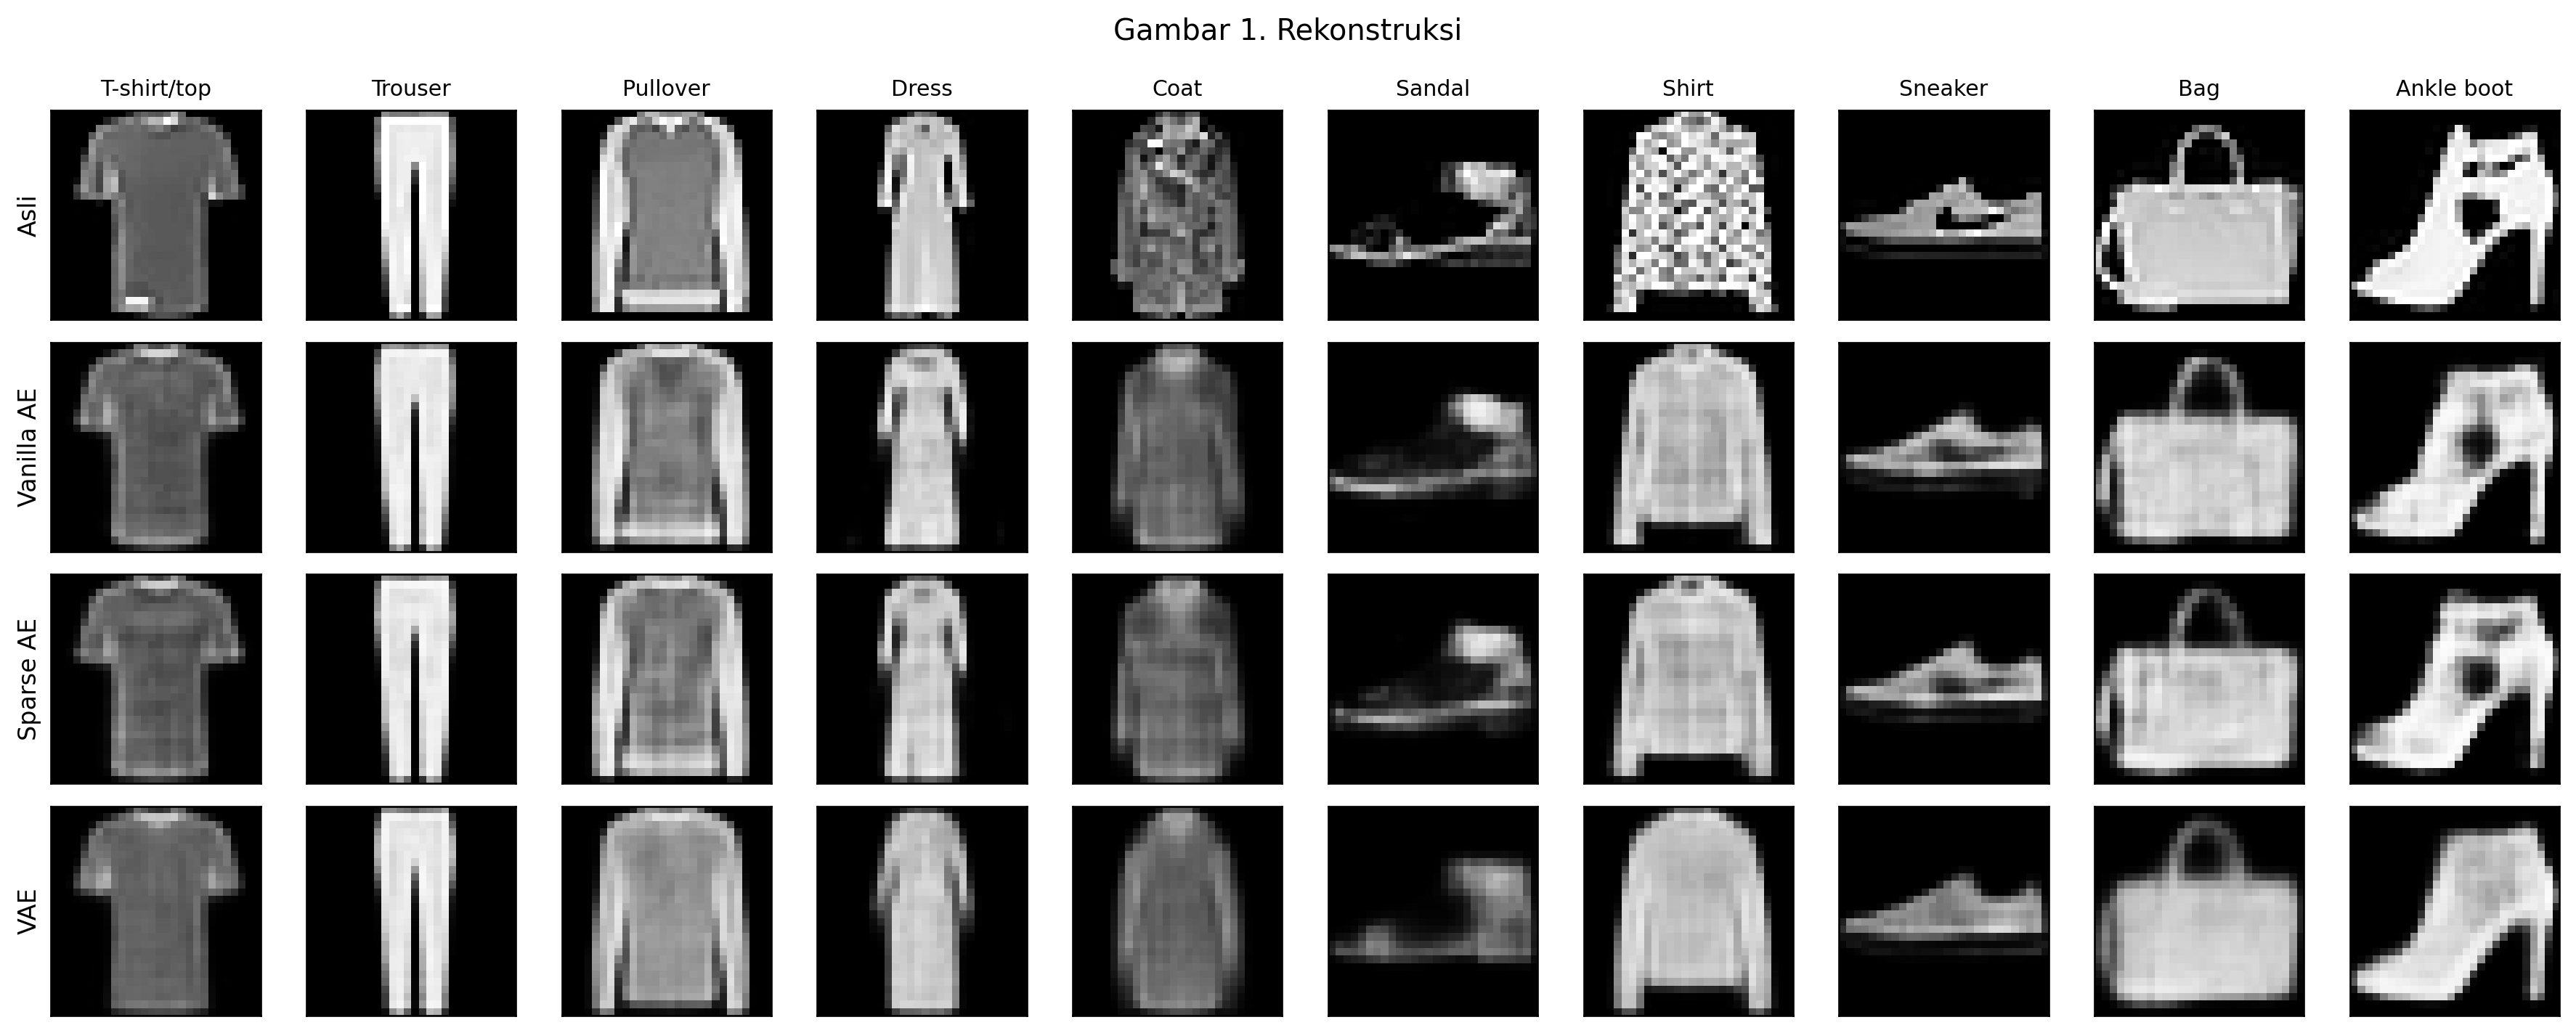

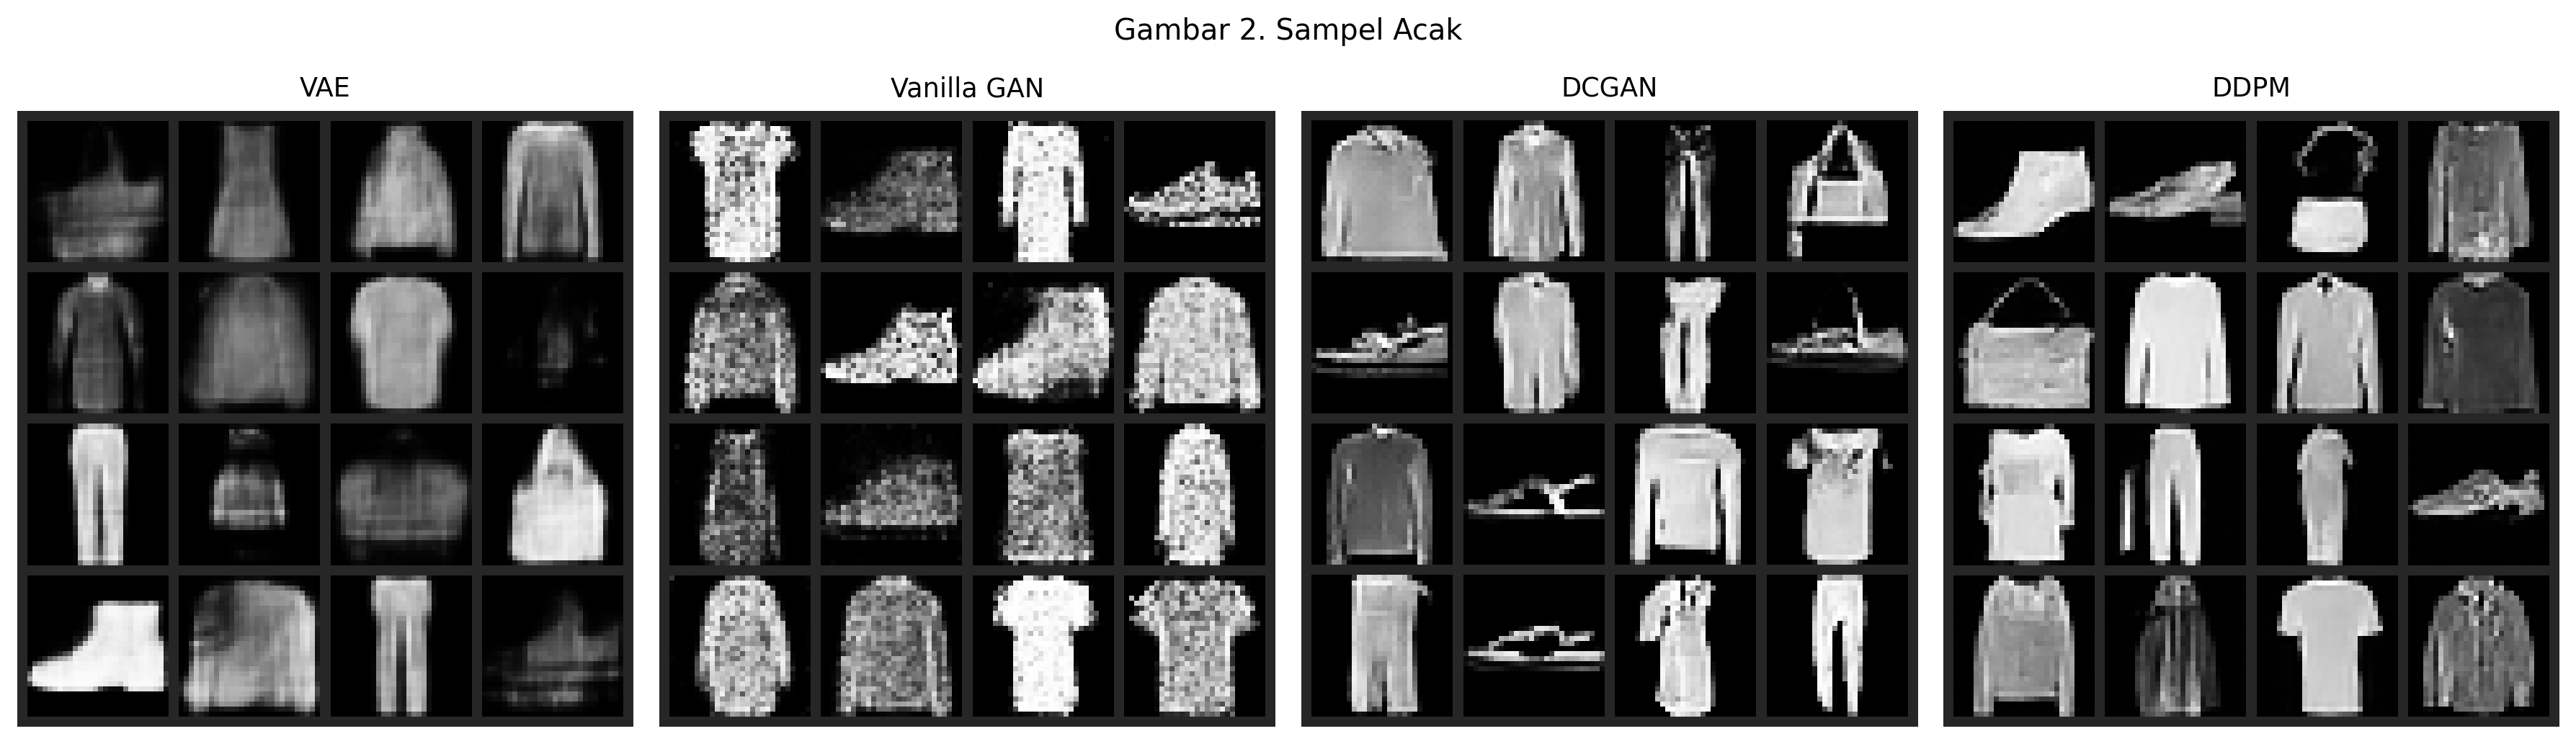

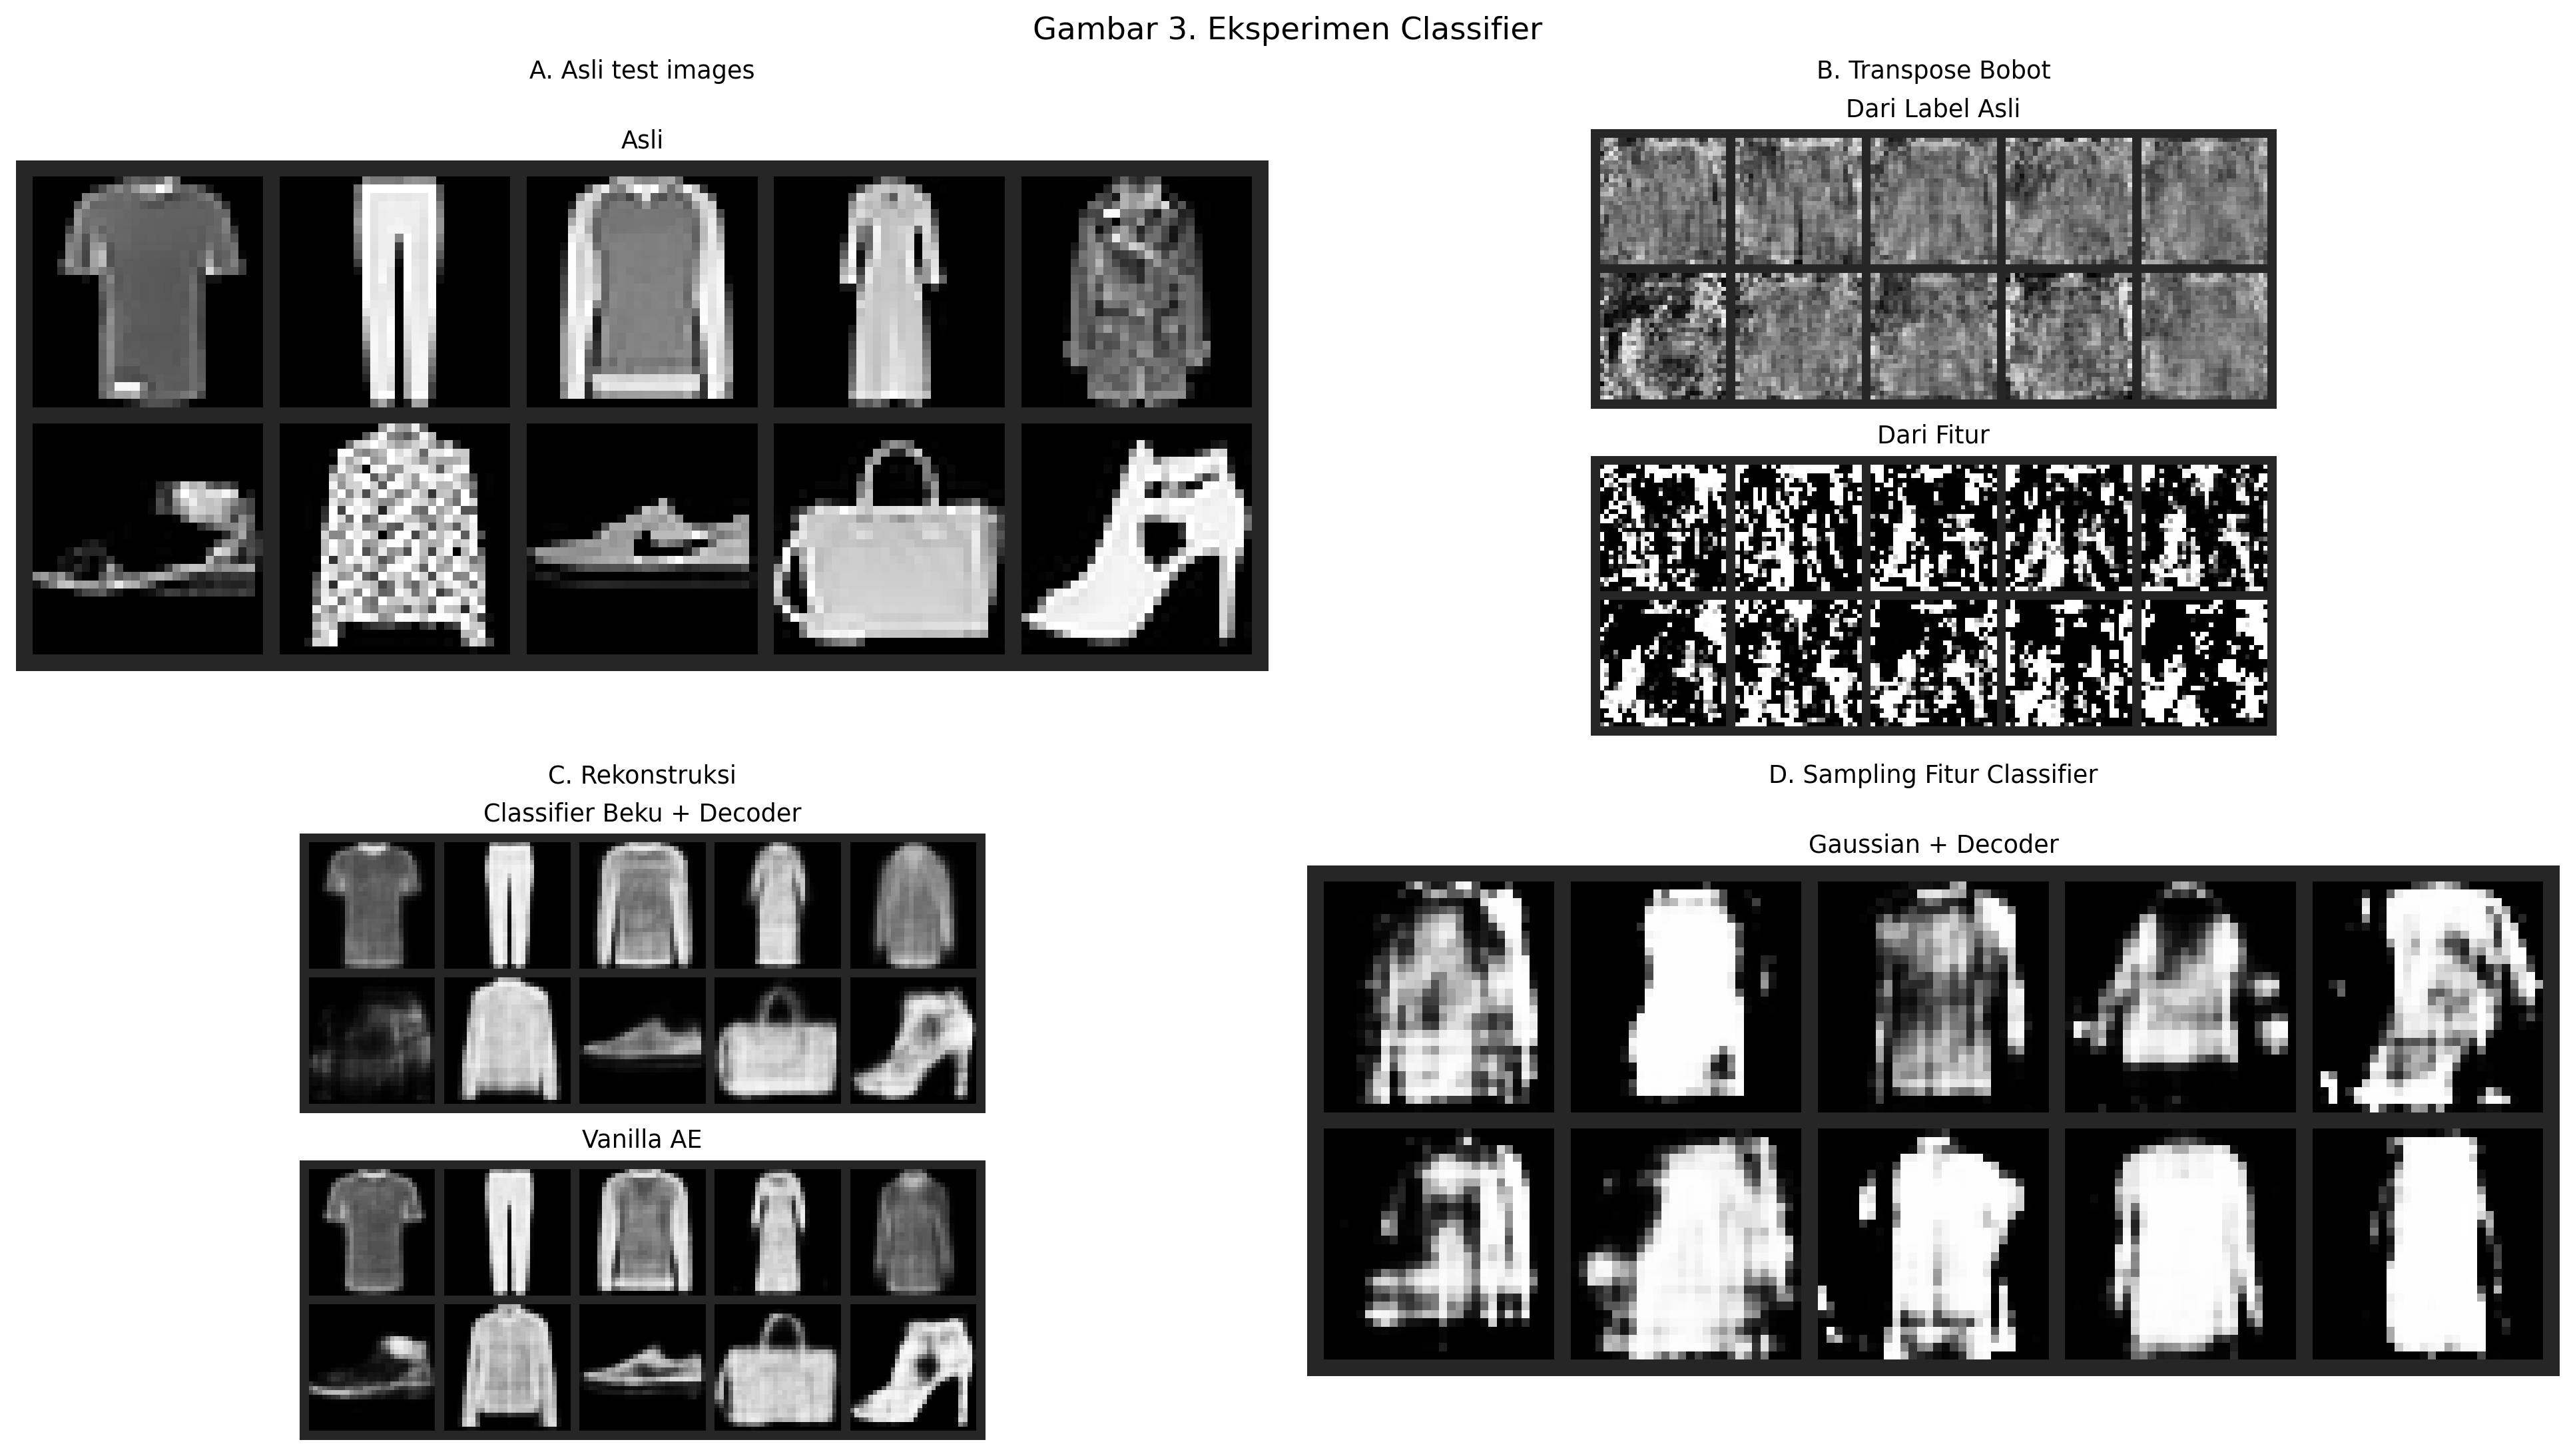

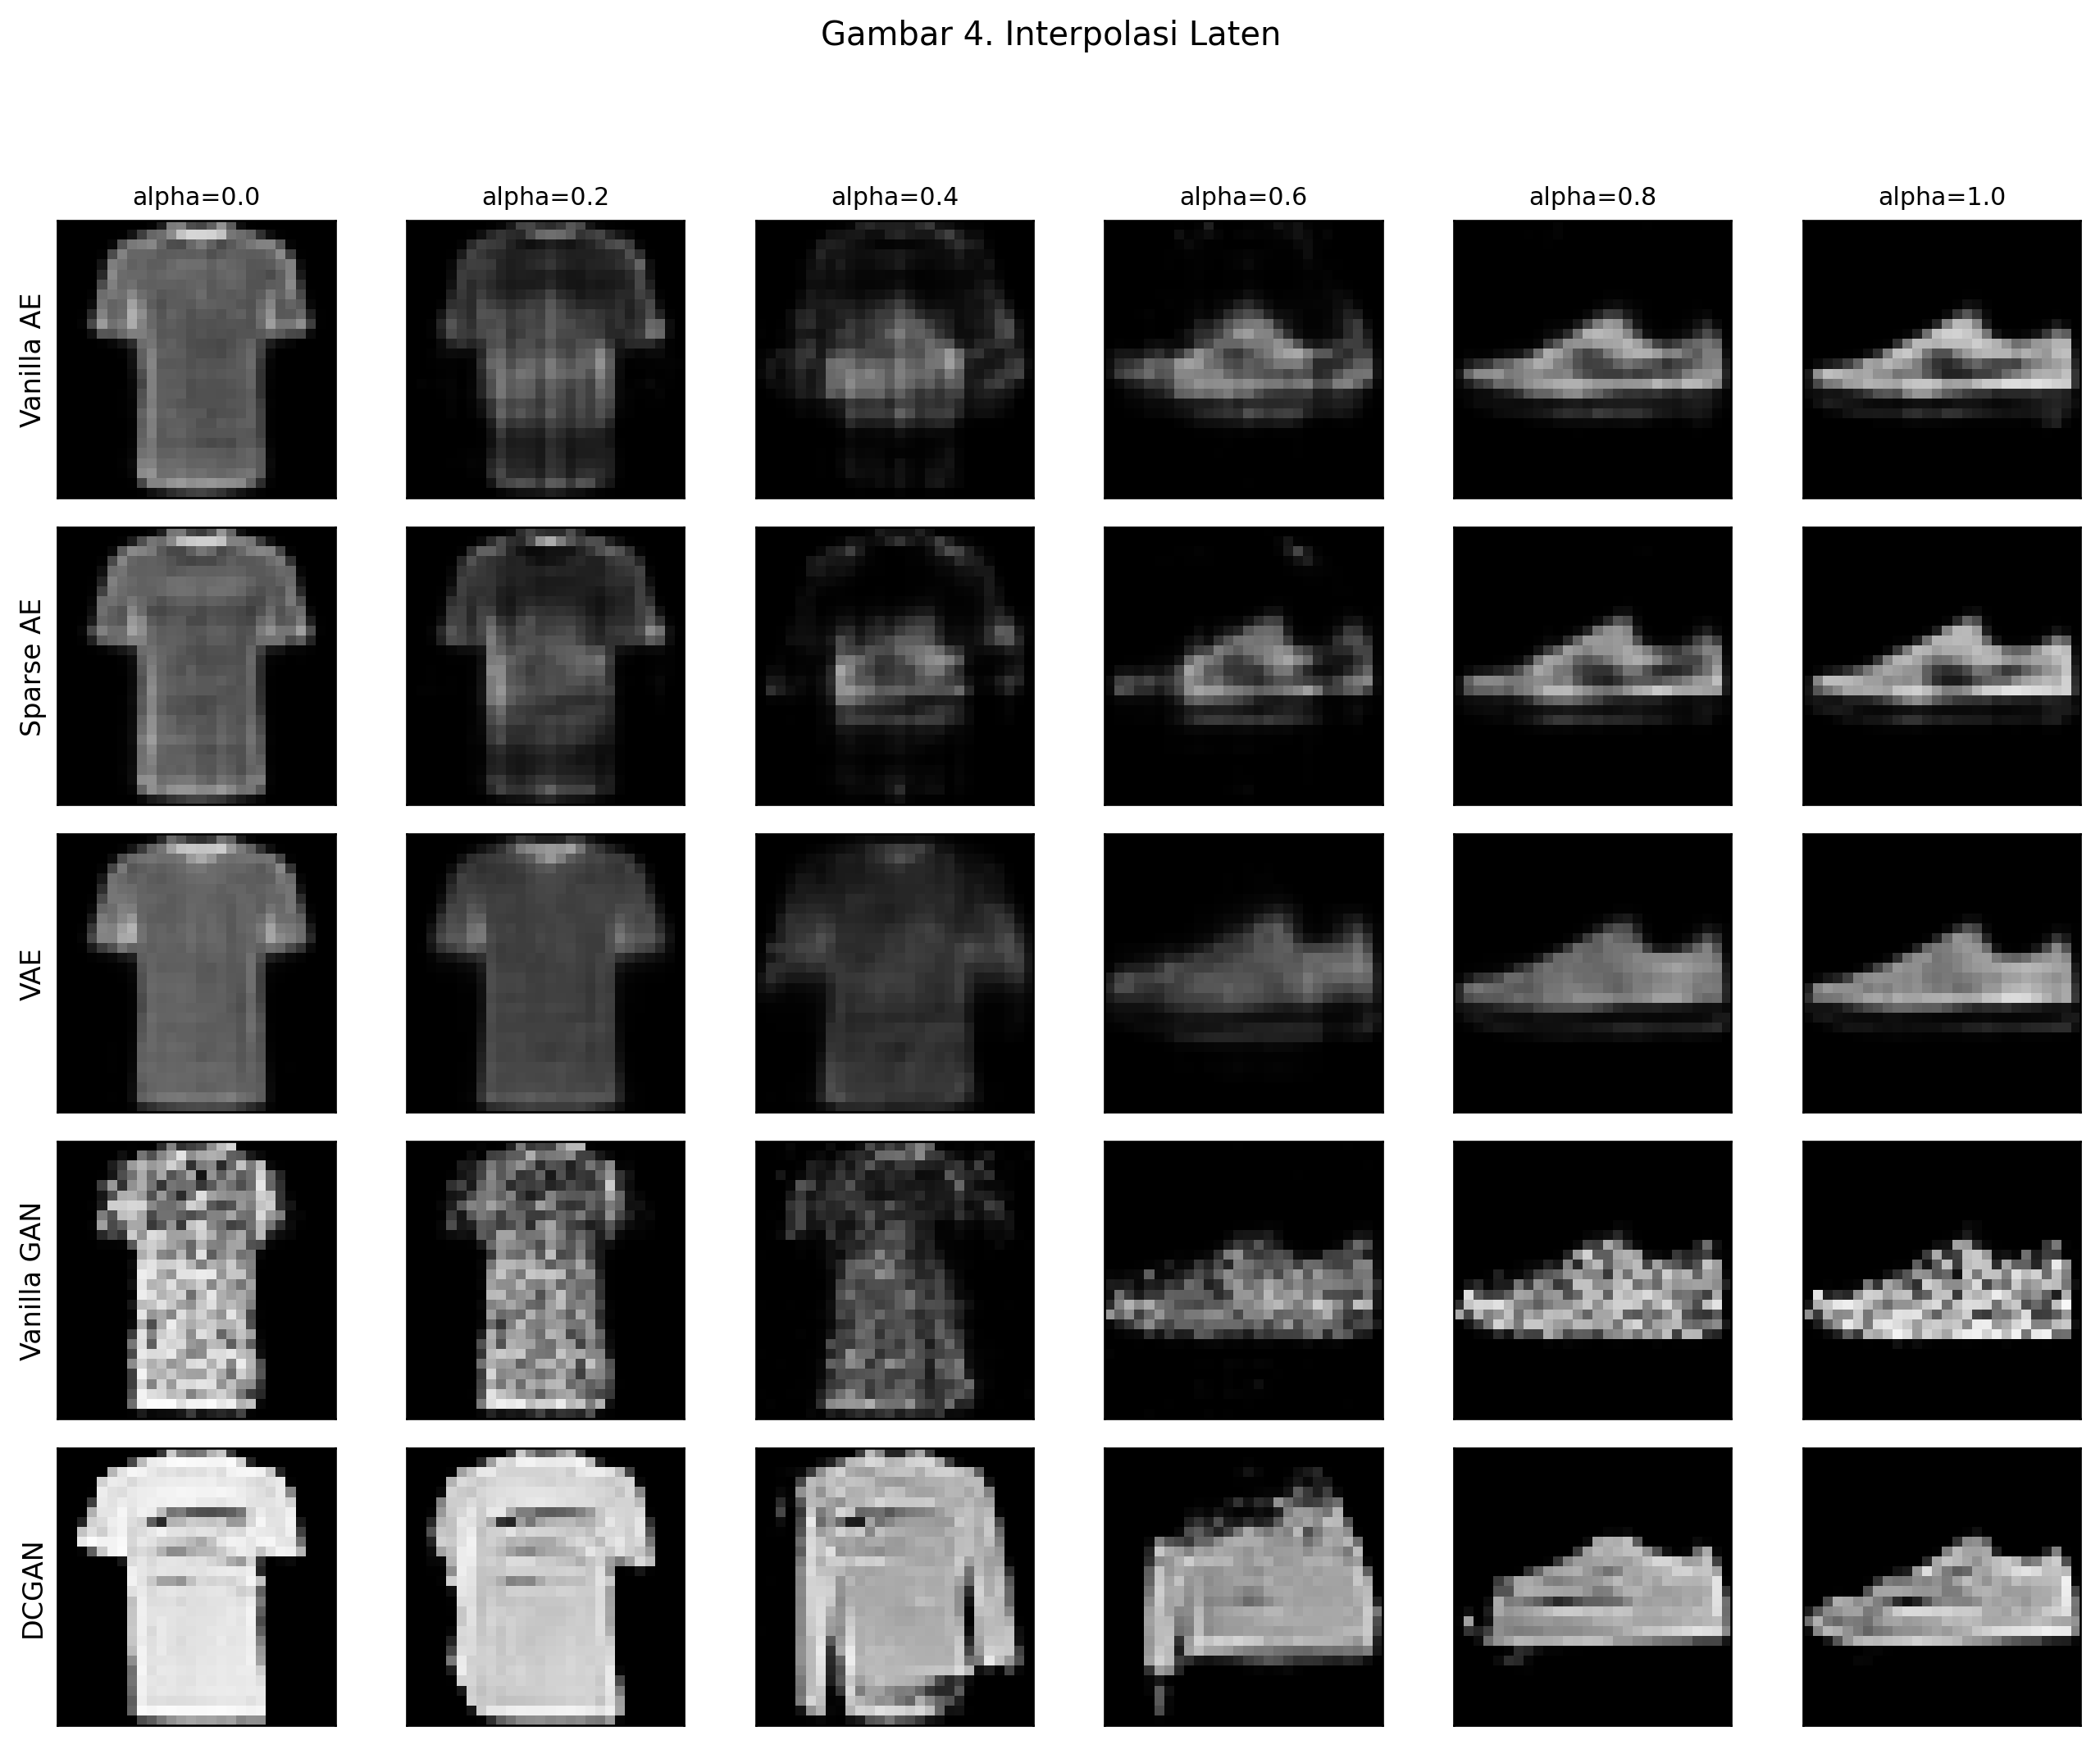

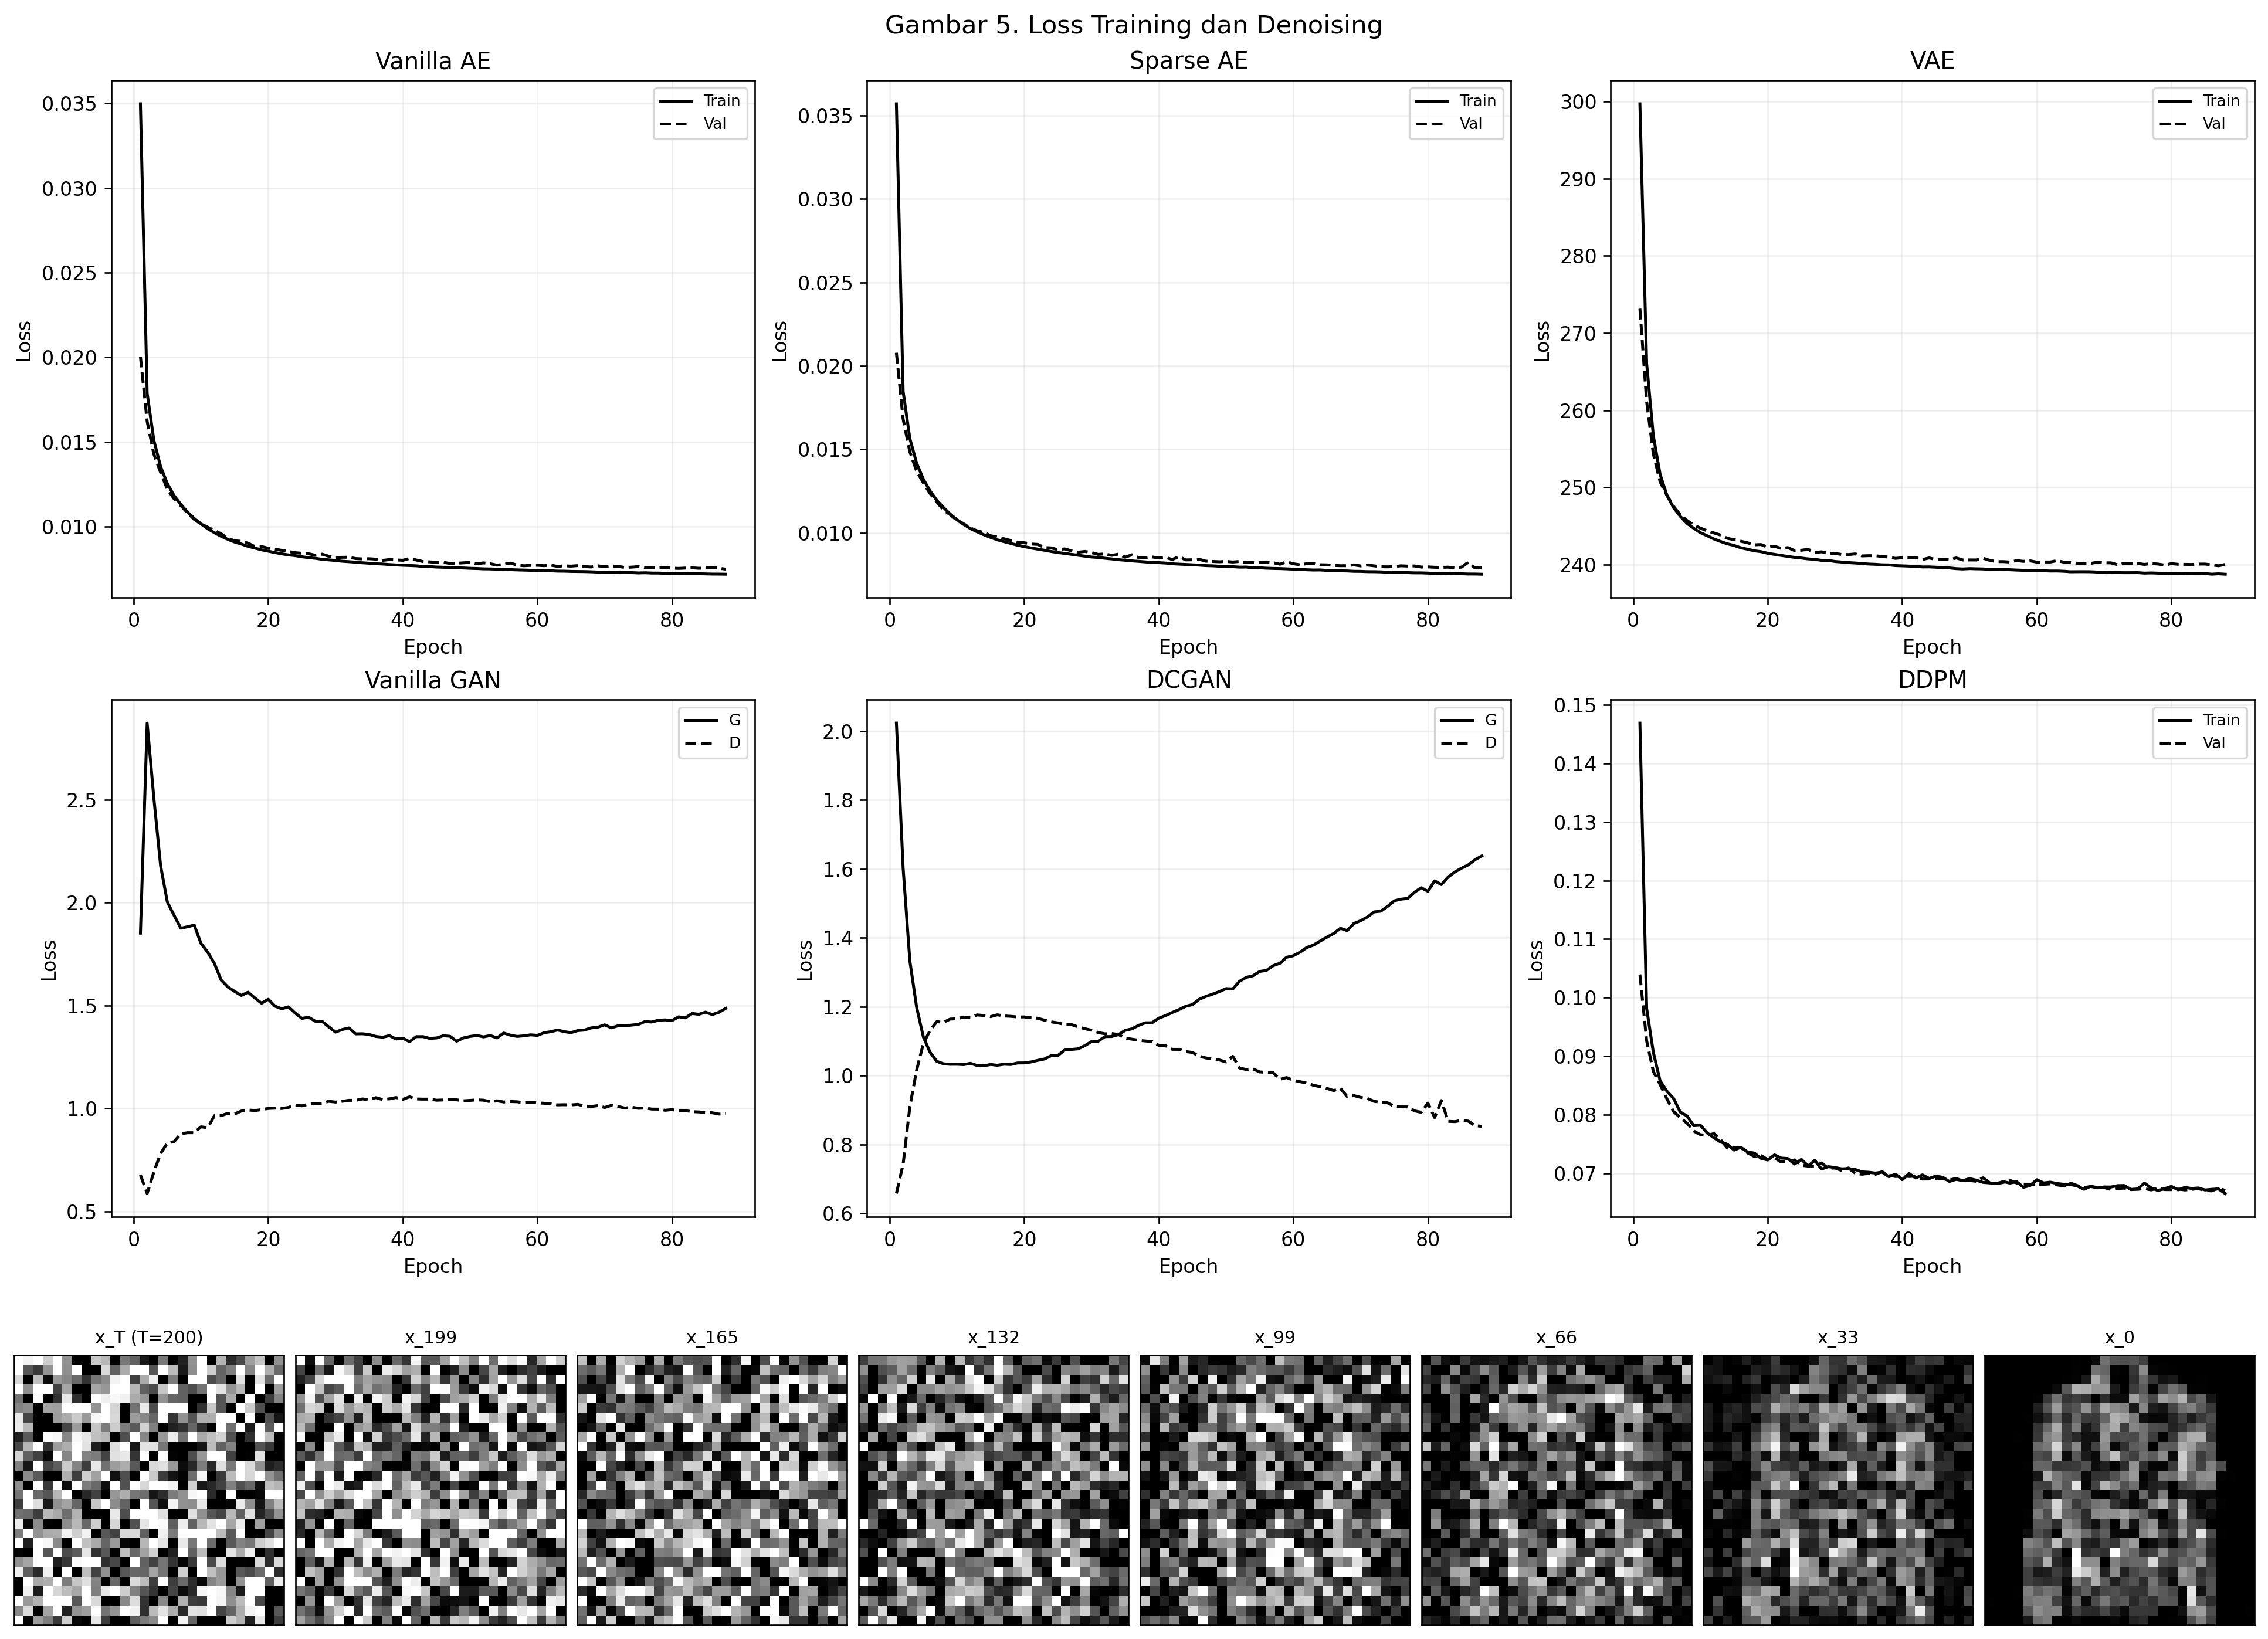

In [24]:
for path in sorted((out / 'figures').glob('fig*.png')):
    display(DisplayImage(filename=str(path), width=1100))

## Cek Hasil


In [25]:
def audit(out, allow_smoke=False):
    def read(name):
        return json.loads((out / name).read_text(encoding='utf-8'))

    checks, failures = [], []
    def check(ok, message):
        (checks if ok else failures).append(message)

    cfg = read('config.json')
    split = np.load(out / 'split_indices.npz')
    parts = [split[name] for name in ['train', 'val', 'test']]
    check([len(x) for x in parts] == [56000, 7000, 7000], 'Ukuran data 80/10/10')
    check(len(np.unique(np.concatenate(parts))) == 70000, 'Data tidak tumpang tindih')
    rows = {row['model']: row for row in read('metrics.json')}
    expected = {'ae', 'sparse_ae', 'vae', 'gan', 'dcgan', 'ddpm', 'frozen_decoder'}
    check(set(rows) == expected, 'Semua model sudah dievaluasi')
    for name, row in rows.items():
        keys = ['latency_mean_ms_batch64', 'training_mean_seconds_epoch']
        if name in ('ae', 'sparse_ae', 'vae', 'frozen_decoder'):
            keys += ['test_mse', 'test_psnr_db', 'test_ssim']
        if name in ('vae', 'gan', 'dcgan', 'ddpm'):
            keys += ['fid_inception2048']
        check(all(row[key] is not None and math.isfinite(row[key]) for key in keys),
              f'{name}: metrik valid')
    for name, epochs in cfg['epochs'].items():
        history = read(f'{name}_history.json')
        check([row['epoch'] for row in history] == list(range(1, epochs + 1)),
              f'{name}: semua epoch selesai')
        check(all(math.isfinite(row['train_loss']) for row in history), f'{name}: loss valid')
        check((out / f'checkpoints/{name}_best.pt').is_file(), f'{name}: model tersimpan')
    acc = read('classifier_diagnostics.json')['test_accuracy']
    check(acc >= .88 or (allow_smoke and cfg['smoke']), f'Akurasi classifier: {acc:.2%}')
    figures = ['fig1_reconstructions', 'fig2_random_sampling', 'fig3_classifier_experiments',
               'fig4_latent_interpolation', 'fig5_training_and_diffusion']
    for name in figures:
        check(all((out / 'figures' / f'{name}.{ext}').is_file() for ext in ['png', 'pdf']),
              f'{name}: gambar tersimpan')
    if not cfg['smoke']:
        protocol = read('evaluation_protocol.json')
        check(protocol['test_images'] == 7000 and protocol['fid_real_images'] == 7000 and
              protocol['fid_synthetic_images_per_model'] == 7000, 'Evaluasi memakai 7.000 gambar')
    check(read('progress.json')['stage'] == 'complete', 'Eksperimen selesai')
    result = {'passed': not failures, 'checks_passed': len(checks), 'failures': failures}
    write_json(out / 'audit.json', result)
    return result


## Sumber

| Bagian | Rujukan | Penyesuaian di notebook |
|---|---|---|
| Dataset | [Fashion-MNIST, Zalando](https://github.com/zalandoresearch/fashion-mnist) | Data digabung lalu dibagi 80/10/10 sesuai tugas. |
| AE, Sparse AE, classifier | [Training loop PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) | Model MLP sesuai soal; Sparse AE menambah penalti L1. |
| VAE | [Contoh VAE PyTorch](https://github.com/pytorch/examples/blob/main/vae/main.py) | Reparameterisasi dan BCE + KL; ukuran layer dan laten disesuaikan. |
| GAN dan DCGAN | [Tutorial DCGAN PyTorch](https://github.com/pytorch/tutorials/blob/main/beginner_source/dcgan_faces_tutorial.py) | Alur update G/D, BatchNorm, dan inisialisasi; input satu kanal 28 x 28. |
| DDPM | [OpenAI improved-diffusion](https://github.com/openai/improved-diffusion/blob/main/improved_diffusion/gaussian_diffusion.py) | Cosine schedule dan posterior; U-Net kecil, 200 langkah, tanpa attention/EMA/DDIM. |
| FID | [TorchMetrics](https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance) | Inception-2048; gambar grayscale diulang menjadi RGB. |

